In [13]:
# 1. Força a liberação de qualquer lixo restante na memória do sistema e da GPU
gc.collect()
torch.cuda.empty_cache()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1. Cria uma pasta local rápida
!mkdir -p /content/dataset_local

# 2. Copia os arquivos do Drive para o Colab (Mude o caminho se necessário)
# O comando 'cp -r' copia pastas inteiras.
print("🚀 Copiando arquivos para o disco local (SSD do Colab)...")
!cp -r "/content/drive/MyDrive/MESTRADO IFCE 2025/Dissertação(Implementação)/Implementações/RIM-ONE_DL_organizado2/." /content/dataset_local/
print("✅ Copiado com sucesso!")

🚀 Copiando arquivos para o disco local (SSD do Colab)...
✅ Copiado com sucesso!


In [ ]:
#!rm -rf /content/dataset_local
#print("🗑️ Pasta excluída com sucesso!")

🗑️ Pasta excluída com sucesso!


In [2]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path
from torchvision import transforms
import torchvision.transforms.functional as TF
import random
from sklearn.model_selection import train_test_split

class RIMONEDataset(Dataset):
    def __init__(self, lista_amostras, split='treino', rot_limit=15, bright_limit=0.3):
        self.samples = lista_amostras
        self.split = split
        self.rot_limit = rot_limit
        self.bright_limit = bright_limit

    def transform(self, image, cup, disc, is_glaucoma):
        image = TF.resize(image, (224, 224), interpolation=transforms.InterpolationMode.BILINEAR)
        cup = TF.resize(cup, (224, 224), interpolation=transforms.InterpolationMode.NEAREST)
        disc = TF.resize(disc, (224, 224), interpolation=transforms.InterpolationMode.NEAREST)

        # Data Augmentation aplicada estritamente no bloco de treino
        if self.split == 'treino':
            prob_base = 0.8 if is_glaucoma else 0.6

            if random.random() < prob_base:
                image = TF.hflip(image); cup = TF.hflip(cup); disc = TF.hflip(disc)
            if random.random() < prob_base:
                image = TF.vflip(image); cup = TF.vflip(cup); disc = TF.vflip(disc)

            if is_glaucoma or (random.random() < 0.5):
                angle = random.uniform(-self.rot_limit, self.rot_limit)
                image = TF.rotate(image, angle)
                cup = TF.rotate(cup, angle, interpolation=transforms.InterpolationMode.NEAREST)
                disc = TF.rotate(disc, angle, interpolation=transforms.InterpolationMode.NEAREST)

            if random.random() < prob_base:
                b_min, b_max = 1.0 - self.bright_limit, 1.0 + self.bright_limit
                brightness_factor = random.uniform(b_min, b_max)
                image = TF.adjust_brightness(image, brightness_factor)

        image = TF.to_tensor(image)
        cup = TF.to_tensor(cup)
        disc = TF.to_tensor(disc)
        mask = torch.cat([cup, disc], dim=0)
        mask = (mask > 0.5).float()

        return image, mask

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        amostra = self.samples[idx]
        img_pil = Image.open(amostra['image']).convert("RGB")
        cup_pil = Image.open(amostra['cup']).convert("L")
        disc_pil = Image.open(amostra['disc']).convert("L")
        img_tensor, mask_tensor = self.transform(img_pil, cup_pil, disc_pil, amostra['label'])
        return img_tensor, mask_tensor, amostra['label']


# ==============================================================================
# 🛠️ PIPELINE DE EXTRAÇÃO E DIVISÃO ESTRATIFICADA HOLD-OUT (70 / 30)
# ==============================================================================

# ==============================================================================
# 🛠️ EXTRAÇÃO DA BASE COMPLETA (485 IMAGENS) E DIVISÃO 70/30
# ==============================================================================

CAMINHO_BASE = Path("/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/RIM-ONE_DL_organizado2")

amostras_totais = []

# Varre tanto 'treino' quanto 'teste' para juntar 100% da base antes de dividir
for split_antigo in ['treino', 'teste']:
    for classe in ['Glaucoma', 'Normal']:
        img_dir = CAMINHO_BASE / split_antigo / classe / 'Images'
        mask_dir = CAMINHO_BASE / split_antigo / classe / 'Masks'
        
        if not img_dir.exists():
            continue
            
        todas_mascaras = list(mask_dir.glob("*.png"))

        for img_path in img_dir.glob("*.png"):
            img_id = img_path.stem
            cup_path = [m for m in todas_mascaras if img_id in m.name and "Cup" in m.name]
            disc_path = [m for m in todas_mascaras if img_id in m.name and "Disc" in m.name]

            if cup_path and disc_path:
                amostras_totais.append({
                    'image': img_path,
                    'cup': cup_path[0],
                    'disc': disc_path[0],
                    'label': 1 if classe == 'Glaucoma' else 0
                })

# Captura os rótulos para estratificação balanceada
labels_totais = [a['label'] for a in amostras_totais]

# Divisão Direta Hold-Out 70% Treino e 30% Teste
amostras_treino, amostras_teste, _, y_teste = train_test_split(
    amostras_totais, labels_totais, test_size=0.30, stratify=labels_totais, random_state=42
)

# Instanciação dos dois subconjuntos isolados
dataset_treino = RIMONEDataset(amostras_treino, split='treino')
dataset_teste  = RIMONEDataset(amostras_teste, split='teste')

print("="*60)
print(f"📊 SPLIT ESTRATIFICADO DA BASE RIM-ONE DL CONCLUÍDO (70/30):")
print("="*60)
print(f"➜ 🟢 Treino (70%): {len(dataset_treino)} imagens")
print(f"➜ 🔵 Teste (30%):  {len(dataset_teste)} imagens")
print(f"📐 Total Geral:   {len(amostras_totais)} imagens")
print("="*60)

print(f"Treino - Glaucoma: {sum([a['label'] for a in amostras_treino])} | Normal: {len(amostras_treino) - sum([a['label'] for a in amostras_treino])}")
print(f"Teste  - Glaucoma: {sum([a['label'] for a in amostras_teste])} | Normal: {len(amostras_teste) - sum([a['label'] for a in amostras_teste])}")

📊 SPLIT ESTRATIFICADO DA BASE RIM-ONE DL CONCLUÍDO (70/30):
➜ 🟢 Treino (70%): 339 imagens
➜ 🔵 Teste (30%):  146 imagens
📐 Total Geral:   485 imagens
Treino - Glaucoma: 120 | Normal: 219
Teste  - Glaucoma: 52 | Normal: 94


In [2]:
# Pega o primeiro item do dataset
img, mask, label = dataset_treino[0]

print(f"Shape da Imagem: {img.shape}") # Deve ser [3, 224, 224]
print(f"Shape da Máscara: {mask.shape}") # Deve ser [2, 224, 224]
print(f"Classe da amostra: {'Glaucoma' if label == 1 else 'Normal'}")

Shape da Imagem: torch.Size([3, 224, 224])
Shape da Máscara: torch.Size([2, 224, 224])
Classe da amostra: Normal


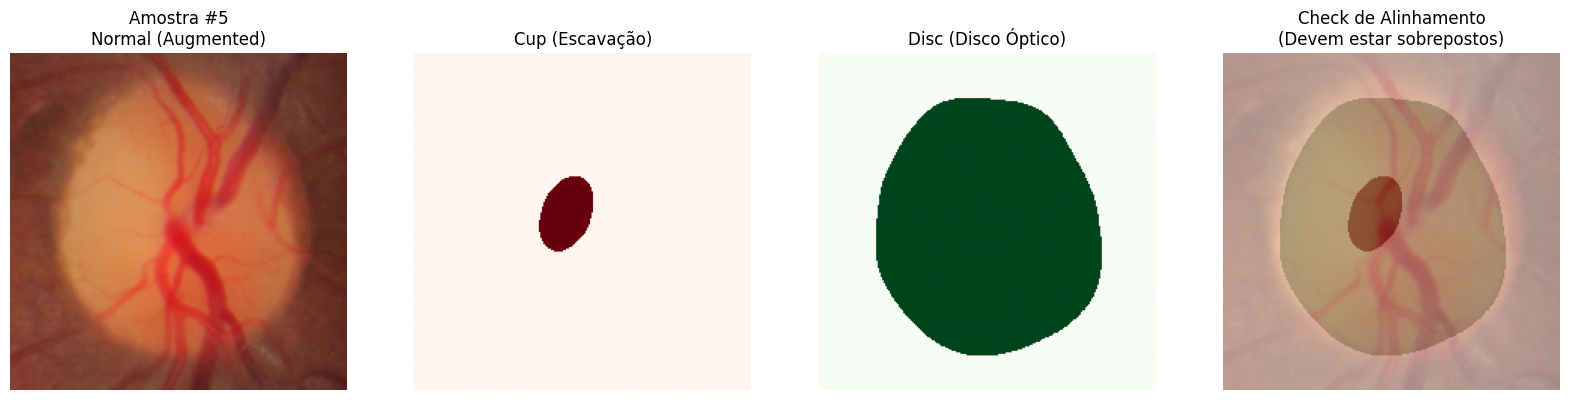

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import random

def verificar_augmentation(dataset, idx=None):
    # 1. Escolhe um índice (se não informar, pega um aleatório)
    if idx is None:
        idx = random.randint(0, len(dataset) - 1)

    # 2. Pega os dados (o __getitem__ vai aplicar o Augmentation automaticamente)
    img, mask, label = dataset[idx]

    # 3. Converte tensores para formato de imagem (H, W, C)
    img_plot = img.permute(1, 2, 0).numpy()
    cup_mask = mask[0].numpy()
    disc_mask = mask[1].numpy()

    # 4. Configura os subplots
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    classe_str = "Glaucoma" if label == 1 else "Normal"

    # Imagem Original Transformada
    ax[0].imshow(img_plot)
    ax[0].set_title(f"Amostra #{idx}\n{classe_str} (Augmented)")
    ax[0].axis('off')

    # Canal do Cup
    ax[1].imshow(cup_mask, cmap='Reds')
    ax[1].set_title("Cup (Escavação)")
    ax[1].axis('off')

    # Canal do Disc
    ax[2].imshow(disc_mask, cmap='Greens')
    ax[2].set_title("Disc (Disco Óptico)")
    ax[2].axis('off')

    # Check de Alinhamento (Sobreposição)
    ax[3].imshow(img_plot)
    ax[3].imshow(disc_mask, cmap='Greens', alpha=0.3)
    ax[3].imshow(cup_mask, cmap='Reds', alpha=0.3)
    ax[3].set_title("Check de Alinhamento\n(Devem estar sobrepostos)")
    ax[3].axis('off')

    plt.show()

# --- EXECUÇÃO ---
# Rode esta célula várias vezes para ver as variações da mesma imagem!
verificar_augmentation(dataset_treino)

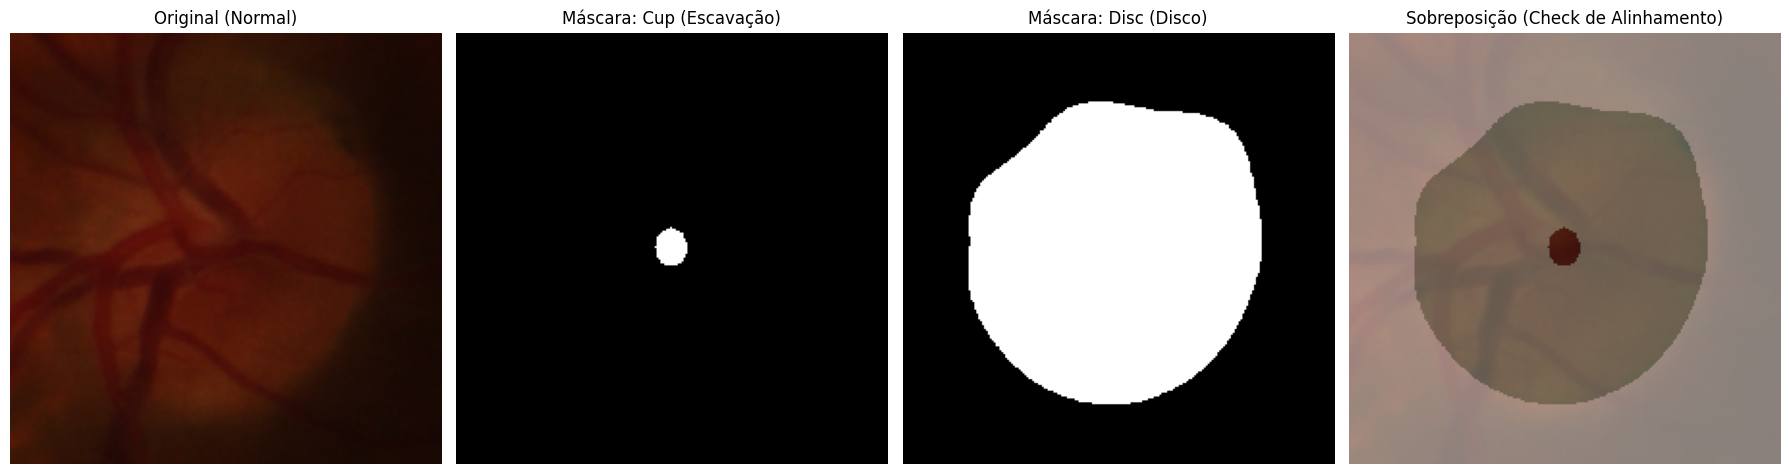

In [5]:
## Visualizando amostra

import matplotlib.pyplot as plt
import numpy as np
import random

def visualizar_amostra(dataset):
    # 1. Escolhe um índice aleatório do dataset
    idx = random.randint(0, len(dataset) - 1)

    # 2. Pega os dados usando o método __getitem__ que criamos
    # img: [3, 224, 224], mask: [2, 224, 224], label: int
    img, mask, label = dataset[idx]

    # 3. Prepara a imagem para exibição
    # O PyTorch usa [Canais, Altura, Largura], mas o Matplotlib usa [Altura, Largura, Canais]
    img_plot = img.permute(1, 2, 0).numpy()

    # 4. Separa as máscaras (Lembrando: Canal 0 = Cup, Canal 1 = Disc)
    cup_mask = mask[0].numpy()
    disc_mask = mask[1].numpy()

    # 5. Configura a visualização com Matplotlib
    fig, ax = plt.subplots(1, 4, figsize=(18, 5))
    classe_str = "Glaucoma" if label == 1 else "Normal"

    # Subplot 1: Imagem Original
    ax[0].imshow(img_plot)
    ax[0].set_title(f"Original ({classe_str})")
    ax[0].axis('off')

    # Subplot 2: Máscara da Escavação (Cup)
    ax[1].imshow(cup_mask, cmap='gray')
    ax[1].set_title("Máscara: Cup (Escavação)")
    ax[1].axis('off')

    # Subplot 3: Máscara do Disco (Disc)
    ax[2].imshow(disc_mask, cmap='gray')
    ax[2].set_title("Máscara: Disc (Disco)")
    ax[2].axis('off')

    # Subplot 4: Sobreposição (Overlay) para conferir o alinhamento
    ax[3].imshow(img_plot)
    # Desenha o Disco em verde (com transparência) e o Cup em vermelho
    ax[3].imshow(disc_mask, cmap='Greens', alpha=0.3)
    ax[3].imshow(cup_mask, cmap='Reds', alpha=0.3)
    ax[3].set_title("Sobreposição (Check de Alinhamento)")
    ax[3].axis('off')

    plt.tight_layout()
    plt.show()

# Executa a visualização
visualizar_amostra(dataset_treino)

In [7]:
### Verificação do caminho.

import os
from pathlib import Path

# O caminho que você usou
#CAMINHO_BASE = "/content/drive/MyDrive/MESTRADO IFCE 2025/Dissertação(Implementação)/Implementações/RIM-ONE_DL_organizado2"

CAMINHO_BASE = "/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/RIM-ONE_DL_organizado2"

# Teste de existência
if os.path.exists(CAMINHO_BASE):
    print("✅ Sucesso: O caminho base existe!")
    # Tenta listar uma pasta interna para ter 100% de certeza
    teste_pasta = Path(CAMINHO_BASE) / "treino" / "Glaucoma" / "Images"
    if teste_pasta.exists():
        qtd = len(os.listdir(teste_pasta))
        print(f"✅ Pasta de imagens encontrada! Existem {qtd} arquivos dentro dela.")
    else:
        print("❌ Erro: O caminho base existe, mas não achei '/treino/Glaucoma/Images' dentro dele.")
else:
    print("❌ Erro: O CAMINHO_BASE não foi encontrado. Verifique se o Drive está montado.")

✅ Sucesso: O caminho base existe!
✅ Pasta de imagens encontrada! Existem 116 arquivos dentro dela.


In [3]:
# ==============================================================================
# 📦 CRIAÇÃO DOS DATALOADERS (HOLD-OUT 70/30)
# ==============================================================================

from torch.utils.data import DataLoader

# 1. Configurações de Performance e Hiperparâmetros
BATCH_SIZE = 4   # Pode ajustar conforme a VRAM disponível (ex: 4, 8 ou 16)
NUM_WORKERS = 0  # Mantido em 0 para estabilidade local (use 2 ou 4 no Colab/Linux)

# 2. Instanciação dos Datasets com a divisão 70/30
dataset_treino = RIMONEDataset(amostras_treino, split='treino')
dataset_teste  = RIMONEDataset(amostras_teste, split='teste')

# 3. Construção e Inicialização das Filas (Loaders)
if len(dataset_treino) > 0:
    train_loader = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    test_loader  = DataLoader(dataset_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    
    print(f"🚀 DataLoaders (70/30) prontos com sucesso!")
    print(f"📦 Batch Size definido: {BATCH_SIZE} | Workers ativos: {NUM_WORKERS}")
    print(f"==========================================================")
    print(f"🖼️  Lotes de Treino (70%): {len(train_loader)} ({len(dataset_treino)} imagens)")
    print(f"🖼️  Lotes de Teste  (30%): {len(test_loader)} ({len(dataset_teste)} imagens)")
    print(f"==========================================================")
else:
    print("⚠️ Atenção: A lista de amostras de treino está vazia. Verifique a célula anterior!")

🚀 DataLoaders (70/30) prontos com sucesso!
📦 Batch Size definido: 4 | Workers ativos: 0
🖼️  Lotes de Treino (70%): 85 (339 imagens)
🖼️  Lotes de Teste  (30%): 37 (146 imagens)


In [4]:
## Arquitetura da U-Net

import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    """Bloco duplo de Convolução 3x3 -> BatchNorm -> ReLU"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    """
    U-Net clássica adaptada para segmentação de retinografias (OD / OC)
    Entrada:  [Batch, 3, 224, 224]
    Saída:    [Batch, 2, 224, 224] (Canal 0: Cup/Escavação | Canal 1: Disc/Disco)
    """
    def __init__(self, in_channels=3, out_channels=2, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # --- CAMINHO DE CONTRAÇÃO (ENCODER) ---
        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        # --- BOTTLENECK ---
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        # --- CAMINHO DE EXPANSÃO (DECODER) ---
        for feature in reversed(features):
            self.ups.append(
                nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2)
            )
            self.ups.append(DoubleConv(feature * 2, feature))

        # --- CAMADA FINAL DE SAÍDA ---
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        # Encoder
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Inverte as conexões para o decoder
        skip_connections = skip_connections[::-1]

        # Decoder
        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)  # Upsampling / ConvTranspose
            skip_connection = skip_connections[idx // 2]

            # Ajuste de dimensões se houver desalinhamento por arredondamento
            if x.shape != skip_connection.shape:
                x = F.interpolate(x, size=skip_connection.shape[2:], mode="bilinear", align_corners=True)

            # Concatenação das feições (Skip Connection)
            concat_x = torch.cat((skip_connection, x), dim=1)
            x = self.ups[idx + 1](concat_x)  # DoubleConv

        return self.final_conv(x)


# --- TESTE RÁPIDO DE SANIDADE DO MODELO ---
if __name__ == "__main__":
    modelo = UNet(in_channels=3, out_channels=2)
    tensor_teste = torch.randn((4, 3, 224, 224)) # Batch = 4, Imagem 224x224
    saida = modelo(tensor_teste)
    
    print("✅ U-Net instanciada com sucesso!")
    print(f"   • Dimensão da Entrada: {tensor_teste.shape}")
    print(f"   • Dimensão da Saída:   {saida.shape}") # Esperado: [4, 2, 224, 224]

✅ U-Net instanciada com sucesso!
   • Dimensão da Entrada: torch.Size([4, 3, 224, 224])
   • Dimensão da Saída:   torch.Size([4, 2, 224, 224])


In [5]:
# Definindo o dispositivo (GPU se disponível, senão CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Criando a instância da TransUNet para 2 canais de saída (Cup e Disc)
model = UNet(in_channels=3, out_channels=2).to(device)

# Colocando em modo de avaliação (desativa dropouts e batchnorm training)
model.eval()

print(f"Modelo pronto e carregado no: {device}")

Modelo pronto e carregado no: cuda


In [6]:
# 1. Pegamos uma imagem real do seu dataset de teste
# O dataset_teste foi o que criamos lá atrás com a classe RIMONEDataset
img_tensor, mask_tensor, label = dataset_teste[0]

# 2. O PyTorch espera um lote (Batch). Como temos só 1 imagem,
# adicionamos uma dimensão extra no início usando .unsqueeze(0)
# De [3, 224, 224] vai para [1, 3, 224, 224]
input_batch = img_tensor.unsqueeze(0).to(device)

# 3. Passamos a imagem pela rede
with torch.no_grad(): # Desativa o cálculo de gradientes para economizar memória
    output = model(input_batch)

print(f"Formato da imagem de entrada: {input_batch.shape}")
print(f"Formato da máscara gerada: {output.shape}")

if output.shape == (1, 2, 224, 224):
    print("\n✅ SUCESSO! A TransUNet processou a imagem e gerou os 2 canais esperados.")
else:
    print("\n❌ Erro nas dimensões de saída.")

Formato da imagem de entrada: torch.Size([1, 3, 224, 224])
Formato da máscara gerada: torch.Size([1, 2, 224, 224])

✅ SUCESSO! A TransUNet processou a imagem e gerou os 2 canais esperados.


In [7]:
def medir_desempenho_completo(modelo, loader, dispositivo):
    """
    VERSÃO ALINHADA COM A AVALIAÇÃO DETALHADA MANUAL.
    Garante que o Random Search use a mesma régua que você usou no GA.
    """
    modelo.eval()

    # Acumuladores: [Dice_Disc, IoU_Disc, Dice_Cup, IoU_Cup]
    scores = [0.0, 0.0, 0.0, 0.0]
    total_batches = len(loader)
    
    if total_batches == 0:
        return [0.0, 0.0, 0.0, 0.0]

    with torch.no_grad():
        for imagens, mascaras, _ in loader:
            imagens, mascaras = imagens.to(dispositivo), mascaras.to(dispositivo)

            # 1. Predição e Binarização (Habilitado para Sigmoid por canal)
            outputs = torch.sigmoid(modelo(imagens))
            preds = (outputs > 0.5).float()

            for c in range(2):
                # 2. Cálculos de Interseção e União
                inter = (preds[:, c] * mascaras[:, c]).sum()
                soma_dice = preds[:, c].sum() + mascaras[:, c].sum()
                uniao = soma_dice - inter

                # 3. Constante de suavização 1e-7 para estabilidade numérica
                d = (2. * inter + 1e-7) / (soma_dice + 1e-7)
                i = (inter + 1e-7) / (uniao + 1e-7)

                # 4. Distribuição nos acumuladores baseada no mapeamento [Cup, Disc]
                if c == 1: # DISCO ÓPTICO (Canal 1)
                    scores[0] += d.item()
                    scores[1] += i.item()
                else:      # ESCAVAÇÃO / CUP (Canal 0)
                    scores[2] += d.item()
                    scores[3] += i.item()

    # 5. Médias Finais por batch
    resultados_finais = [s / total_batches for s in scores]

    # Retorna [Média_Dice_Disco, Média_IoU_Disco, Média_Dice_Cup, Média_IoU_Cup]
    return resultados_finais

print("✅ Métrica Dice/IoU configurada para o Random Search de forma segura.")

✅ Métrica Dice/IoU configurada para o Random Search de forma segura.


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# --- 1. FUNÇÃO DE PERDA (DICE LOSS POR CANAL COM AUDITORIA) ---
def dice_loss_rigorosa(pred, target, smooth=1e-6, return_individual=False):
    # Aplicamos Sigmoid para transformar a saída da rede em probabilidade (0 a 1)
    pred_sig = torch.sigmoid(pred)

    # Somamos nas dimensões de Batch(0), largura(2) e altura(3)
    # para manter os canais separados no cálculo
    intersection = (pred_sig * target).sum(dim=(0, 2, 3))
    total_area = pred_sig.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))

    # Cálculo do Dice para cada canal (0: Cup/Escavação, 1: Disc/Disco)
    dice_per_channel = (2. * intersection + smooth) / (total_area + smooth)

    # Se pedirmos individual, ele retorna o tensor [Dice_Cup, Dice_Disc] para o print
    if return_individual:
        return dice_per_channel

    # Para o treinamento, retornamos a média do erro (1 - Dice)
    return 1 - dice_per_channel.mean()

# Instanciação da perda BCE global
criterion_bce = nn.BCEWithLogitsLoss()

# --- 2. FUNÇÃO DE TREINAMENTO POR ÉPOCA ---
def treinar_uma_epoca_rigorosa(model, loader, optimizer, device):
    model.train()
    loss_total = 0

    for imagens, mascaras, _ in loader:
        imagens, mascaras = imagens.to(device), mascaras.to(device)
        optimizer.zero_grad()

        outputs = model(imagens)

        # Perda combinada (BCE pixel a pixel + Dice por forma)
        loss_bce = criterion_bce(outputs, mascaras)
        loss_dice = dice_loss_rigorosa(outputs, mascaras)

        loss_combinada = loss_bce + loss_dice

        loss_combinada.backward()
        optimizer.step()

        loss_total += loss_combinada.item()

    return loss_total / len(loader)

print("✅ Funções de perda e treinamento configuradas com sucesso!")
print("💡 Nota: O otimizador será instanciado na célula seguinte, logo após o carregamento da TransUNet.")

✅ Funções de perda e treinamento configuradas com sucesso!
💡 Nota: O otimizador será instanciado na célula seguinte, logo após o carregamento da TransUNet.


In [9]:
# ==============================================================================
# ⚙️ DEFINIÇÃO DOS HIPERPARÂMETROS E PREPARAÇÃO DA U-NET
# ==============================================================================

import torch
import torch.optim as optim
from torch.utils.data import DataLoader

# --- 1. ATRIBUIÇÃO DOS HIPERPARÂMETROS DA U-NET ---
CONFIG_ESCOLHIDA = {
    'lr': 1e-4,        # Mantida a mesma taxa de aprendizado para equidade metodológica
    'rot': 15,         # Rotação para Data Augmentation
    'bright': 0.3      # Variação de brilho para Data Augmentation
}

BATCH_SIZE = 4  # Mantido em 4 para perfeito uso da VRAM

print(f"⚙️ Aplicando a configuração selecionada para a U-Net:")
print(f"   -> Taxa de Aprendizado (LR): {CONFIG_ESCOLHIDA['lr']}")
print(f"   -> Augmentation: Rotação {CONFIG_ESCOLHIDA['rot']}° | Brilho {CONFIG_ESCOLHIDA['bright']}")
print(f"   -> Batch Size: {BATCH_SIZE}\n")

# --- 2. RE-INSTANCIAÇÃO DOS DATASETS E DATALOADERS (HOLD-OUT 70/30) ---
dataset_treino = RIMONEDataset(amostras_treino, split='treino', rot_limit=CONFIG_ESCOLHIDA['rot'], bright_limit=CONFIG_ESCOLHIDA['bright'])
dataset_teste  = RIMONEDataset(amostras_teste, split='teste') # Teste sem augmentations estocásticas

train_loader = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
test_loader  = DataLoader(dataset_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"🔄 DataLoaders reajustados dinamicamente para o esquema 70/30.")

# --- 3. PREPARAÇÃO DO DISPOSITIVO DE HARDWARE ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"💻 Dispositivo de processamento ativo: {device}")

# --- 4. CONFIGURAÇÃO DA FUNÇÃO DE CRIAÇÃO DO OTIMIZADOR PARA U-NET ---
def configurar_otimizador_unet(model):
    optimizer = optim.Adam(
        model.parameters(), 
        lr=CONFIG_ESCOLHIDA['lr'],
        weight_decay=1e-4 # Proteção contra overfitting
    )
    return optimizer

print("✅ Preparativos para a U-Net concluídos!")

⚙️ Aplicando a configuração selecionada para a U-Net:
   -> Taxa de Aprendizado (LR): 0.0001
   -> Augmentation: Rotação 15° | Brilho 0.3
   -> Batch Size: 4

🔄 DataLoaders reajustados dinamicamente para o esquema 70/30.
💻 Dispositivo de processamento ativo: cuda
✅ Preparativos para a U-Net concluídos!


In [10]:
import torch
import torch.nn as nn
import gc
import os
from tqdm.notebook import tqdm

def rodar_execucao_fold_unet(fold_id, loader_treino, loader_teste, config, device, total_epocas=100, paciencia=20):
    """ 
    Executa o ciclo completo de treinamento para um Fold ou Hold-Out com a U-Net,
    garantindo liberação estrita de VRAM ao finalizar.
    """
    # 🧹 Faxina preventiva antes de alocar a rede
    gc.collect()
    torch.cuda.empty_cache()

    criterion_bce = nn.BCEWithLogitsLoss()
    caminho_checkpoint = f"temp_unet_fold_{fold_id}.pth"
    
    # 1. Instanciação dinâmica da U-Net
    modelo = UNet(
        in_channels=3, 
        out_channels=2
    ).to(device)
    
    otimizador = torch.optim.Adam(
        modelo.parameters(), 
        lr=config['lr'],
        weight_decay=1e-4
    )
    
    # Scheduler para decair LR se estagnar por 5 épocas
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        otimizador, mode='max', factor=0.5, patience=5
    )
    
    melhor_score_combinado = 0.0
    contador_paciencia = 0
    loss_final = 0.0
    
    print(f"\n🚀 [{fold_id}] Iniciando Treinamento U-Net (Paciência: {paciencia})...")
    
    # 2. LOOP DE ÉPOCAS
    for epoch in range(total_epocas):
        modelo.train()
        loss_acumulada = 0.0
        
        batch_loop = tqdm(loader_treino, desc=f"{fold_id} - Ep {epoch+1}/{total_epocas}", leave=False)
        for imagens, mascaras, _ in batch_loop:
            imagens, mascaras = imagens.to(device), mascaras.to(device)
            
            otimizador.zero_grad()
            saidas = modelo(imagens)
            
            loss = criterion_bce(saidas, mascaras) + dice_loss_rigorosa(saidas, mascaras)
            loss.backward()
            otimizador.step()
            
            loss_acumulada += loss.item()
            
        loss_final = loss_acumulada / len(loader_treino)
        
        # Validação do Fold
        modelo.eval()
        with torch.no_grad():
            m = medir_desempenho_completo(modelo, loader_teste, device)
            # Avalia uma média equilibrada do Dice de Disco (m[0]) e Cup (m[2])
            score_atual = (m[0] * 0.3) + (m[2] * 0.7)
            
        # Atualiza o scheduler com base no desempenho
        scheduler.step(score_atual)
        lr_atual = otimizador.param_groups[0]['lr']
        
        print(f"📊 [{fold_id}][EP {epoch+1:03d}/{total_epocas:03d}] Loss: {loss_final:.4f} | LR: {lr_atual:.1e} | "
              f"VAL DISCO: Dice={m[0]:.4f}, IoU={m[1]:.4f} | "
              f"VAL CUP: Dice={m[2]:.4f}, IoU={m[3]:.4f}")
        
        # Avalia se é a melhor época para salvar os pesos do Fold
        if score_atual > melhor_score_combinado:
            melhor_score_combinado = score_atual
            contador_paciencia = 0
            torch.save(modelo.state_dict(), caminho_checkpoint)
        else:
            contador_paciencia += 1
            
        if contador_paciencia >= paciencia:
            print(f"🛑 Early Stopping acionado no {fold_id} na época {epoch+1}!")
            break
            
    # 3. RECUPERAÇÃO DO MELHOR ESTADO
    if os.path.exists(caminho_checkpoint):
        modelo.load_state_dict(torch.load(caminho_checkpoint, weights_only=True))
        
    metricas = medir_desempenho_completo(modelo, loader_teste, device)
    
    nota_disco = (metricas[0] + metricas[1]) / 2
    nota_cup   = (metricas[2] + metricas[3]) / 2
    nota_final = (nota_disco * 0.20) + (nota_cup * 0.80)
    
    # Guarda o state_dict na RAM antes de desalocar o modelo da GPU
    pesos_finais = modelo.state_dict()
    
    # 🧹 LIMPEZA CRÍTICA DE VRAM
    del modelo, otimizador, scheduler
    gc.collect()
    torch.cuda.empty_cache()
    
    return nota_final, metricas, loss_final, pesos_finais

In [ ]:
## Teste Cross Validation - U-Net (Rim-ONE DL)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import gc
import os
import time
import csv
import numpy as np
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import StratifiedKFold
from tqdm.notebook import tqdm

# --- CONFIGURAÇÃO DE DIRETÓRIOS E DISPOSITIVO ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Diretório de destino para a U-Net
PASTA_DESTINO = "/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/Unet/RIM_ONE_DL/MelhorModelo"

if not os.path.exists(PASTA_DESTINO):
    os.makedirs(PASTA_DESTINO)
    print(f"📁 Pasta de destino configurada em: {PASTA_DESTINO}")

# --- NOMES COMPLETOS DOS ARQUIVOS NA PASTA DESTINO ---
NOME_PROJETO = "UNet_RimOne_KFold_CrossValidation"
ARQUIVO_TXT_LOG = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO}_logs.txt")
ARQUIVO_XLS_CSV = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO}_resultados.csv")
caminho_melhor_modelo_global = os.path.join(PASTA_DESTINO, "UNet_MELHOR_PESO_PROJETO.pth")

def salvar_log_txt(mensagem):
    with open(ARQUIVO_TXT_LOG, "a", encoding="utf-8") as f:
        f.write(mensagem + "\n")
    print(mensagem)

# Inicialização limpa dos arquivos de auditoria
with open(ARQUIVO_TXT_LOG, "w", encoding="utf-8") as f:
    f.write("==================================================\n")
    f.write("📊 DIÁRIO DE VALIDAÇÃO CRUZADA (5-FOLD): U-NET\n")
    f.write("==================================================\n\n")

with open(ARQUIVO_XLS_CSV, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f, delimiter=";")
    writer.writerow(["Fold", "Loss_Final", "Dice_Disco", "IoU_Disco", "Dice_Cup", "IoU_Cup", "Nota_Ponderada", "Tempo_Segundos"])

# --- PREPARAÇÃO DOS DATASETS SEPARADOS PARA O K-FOLD ---
# Criamos duas instâncias: uma ativa para Treino (com augmentation) e uma passiva para Validação/Teste (sem augmentation)
dataset_kfold_treino = RIMONEDataset(
    amostras_totais, 
    split='treino', 
    rot_limit=CONFIG_ESCOLHIDA['rot'], 
    bright_limit=CONFIG_ESCOLHIDA['bright']
)

dataset_kfold_val = RIMONEDataset(
    amostras_totais, 
    split='val', 
    rot_limit=CONFIG_ESCOLHIDA['rot'], 
    bright_limit=CONFIG_ESCOLHIDA['bright']
)

labels_kfold = [amostra['label'] for amostra in amostras_totais]

# StratifiedKFold de 5 dobras
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

historico_metricas = []
historico_tempos = []
historico_losses = []
melhor_nota_geral = -1.0

# --- LAÇO DA VALIDAÇÃO CRUZADA ---
for fold_id, (indices_treino, indices_teste) in enumerate(skf.split(amostras_totais, labels_kfold), 1):
    salvar_log_txt(f"\n▶️ [FOLD {fold_id}/5] Separando subconjuntos de forma estratificada...")
    tempo_inicial = time.time()
    
    # Treino usa o dataset com augmentation | Validação usa o dataset limpo
    sub_treino = Subset(dataset_kfold_treino, indices_treino)
    sub_teste  = Subset(dataset_kfold_val, indices_teste)
    
    loader_treino_fold = DataLoader(sub_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    loader_teste_fold  = DataLoader(sub_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    
    # Executa o treinamento do fold ativo para a U-Net
    nota_final, metricas, loss_final, pesos_do_fold = rodar_execucao_fold_unet(
        fold_id=fold_id,
        loader_treino=loader_treino_fold,
        loader_teste=loader_teste_fold,
        config=CONFIG_ESCOLHIDA,
        device=device
    )
    
    tempo_decorrido = time.time() - tempo_inicial
    
    historico_metricas.append(metricas)
    historico_tempos.append(tempo_decorrido)
    historico_losses.append(loss_final)
    
    # Logs no arquivo TXT
    log_fold = (
        f"   📌 Resultados do Fold {fold_id}:\n"
        f"      - Tempo Computacional: {tempo_decorrido:.2f}s | Loss: {loss_final:.4f}\n"
        f"      - [DISCO] Dice: {metricas[0]:.4f} | IoU: {metricas[1]:.4f}\n"
        f"      - [CUP]   Dice: {metricas[2]:.4f} | IoU: {metricas[3]:.4f}\n"
        f"--------------------------------------------------"
    )
    salvar_log_txt(log_fold)
    
    # Escrita na planilha CSV
    with open(ARQUIVO_XLS_CSV, "a", newline="", encoding="utf-8") as f:
        writer = csv.writer(f, delimiter=";")
        writer.writerow([fold_id, f"{loss_final:.4f}", f"{metricas[0]:.4f}", f"{metricas[1]:.4f}", f"{metricas[2]:.4f}", f"{metricas[3]:.4f}", f"{nota_final:.4f}", f"{tempo_decorrido:.2f}"])
    
    # Atualização do melhor modelo global
    if nota_final > melhor_nota_geral:
        melhor_nota_geral = nota_final
        torch.save(pesos_do_fold, caminho_melhor_modelo_global)
        salvar_log_txt(f"👑 Novo recorde de validação cruzada! Peso global atualizado: {caminho_melhor_modelo_global}")
        
    # Limpeza de memória cache da GPU
    del loader_treino_fold, loader_teste_fold
    torch.cuda.empty_cache()
    gc.collect()

# --- PROCESSAMENTO ESTATÍSTICO CONSOLIDADO ---
dados_np = np.array(historico_metricas)
tempos_np = np.array(historico_tempos)
losses_np = np.array(historico_losses)

log_estatistico = (
    "\n" + "="*60 + "\n"
    "📊 CONSOLIDAÇÃO FINAL DA VALIDAÇÃO CRUZADA U-NET (5-FOLD)\n"
    + "="*60 + "\n"
    f"🟢 DISCO ÓPTICO:\n"
    f"   • Dice Médio: {np.mean(dados_np[:, 0]):.4f} ± {np.std(dados_np[:, 0]):.4f}\n"
    f"   • IoU Médio:  {np.mean(dados_np[:, 1]):.4f} ± {np.std(dados_np[:, 1]):.4f}\n"
    f"🔵 ESCAVAÇÃO ÓPTICA (CUP):\n"
    f"   • Dice Médio: {np.mean(dados_np[:, 2]):.4f} ± {np.std(dados_np[:, 2]):.4f}\n"
    f"   • IoU Médio:  {np.mean(dados_np[:, 3]):.4f} ± {np.std(dados_np[:, 3]):.4f}\n"
    f"📉 LOSS DE TREINAMENTO:\n"
    f"   • Média:      {np.mean(losses_np):.4f} ± {np.std(losses_np):.4f}\n"
    f"⏱️ DESEMPENHO COMPUTACIONAL TEMPORAL:\n"
    f"   • Média por Fold: {np.mean(tempos_np):.2f}s ± {np.std(tempos_np):.2f}s\n"
    f"   • Tempo Total:    {np.sum(tempos_np)/60:.2f} minutos\n"
    + "="*60
)

salvar_log_txt(log_estatistico)

with open(ARQUIVO_XLS_CSV, "a", newline="", encoding="utf-8") as f:
    writer = csv.writer(f, delimiter=";")
    writer.writerow([])
    writer.writerow(["MÉDIA CONSOLIDADA", f"{np.mean(losses_np):.4f}", f"{np.mean(dados_np[:, 0]):.4f}", f"{np.mean(dados_np[:, 1]):.4f}", f"{np.mean(dados_np[:, 2]):.4f}", f"{np.mean(dados_np[:, 3]):.4f}", "", f"{np.mean(tempos_np):.2f}"])
    writer.writerow(["DESVIO PADRÃO", f"{np.std(losses_np):.4f}", f"{np.std(dados_np[:, 0]):.4f}", f"{np.std(dados_np[:, 1]):.4f}", f"{np.std(dados_np[:, 2]):.4f}", f"{np.std(dados_np[:, 3]):.4f}", "", f"{np.std(tempos_np):.2f}"])

print(f"\n🎯 Experimento concluído! Validação Cruzada da U-Net salva na pasta:\n📂 {PASTA_DESTINO}")


▶️ [FOLD 1/5] Separando subconjuntos de forma estratificada...

🚀 [1] Iniciando Treinamento U-Net (Paciência: 20)...


1 - Ep 1/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [1][EP 001/100] Loss: 0.8929 | LR: 1.0e-04 | VAL DISCO: Dice=0.9153, IoU=0.8449 | VAL CUP: Dice=0.6025, IoU=0.4529


1 - Ep 2/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [1][EP 002/100] Loss: 0.6826 | LR: 1.0e-04 | VAL DISCO: Dice=0.9122, IoU=0.8407 | VAL CUP: Dice=0.5570, IoU=0.4105


...

5 - Ep 46/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [5][EP 046/100] Loss: 0.1664 | LR: 2.5e-05 | VAL DISCO: Dice=0.9586, IoU=0.9206 | VAL CUP: Dice=0.8505, IoU=0.7438


5 - Ep 47/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [5][EP 047/100] Loss: 0.1675 | LR: 2.5e-05 | VAL DISCO: Dice=0.9578, IoU=0.9192 | VAL CUP: Dice=0.8443, IoU=0.7347


5 - Ep 48/100:   0%|          | 0/97 [00:00<?, ?it/s]

In [12]:
# ==============================================================================
# 🔄 EXECUÇÃO ISOLADA APENAS DO FOLD 5 (RECOMPOSIÇÃO DO K-FOLD)
# ==============================================================================

import torch
import torch.nn as nn
import gc
import os
import time
import csv
import numpy as np
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import StratifiedKFold

# --- CONFIGURAÇÃO DE DIRETÓRIOS E DISPOSITIVO ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PASTA_DESTINO = "/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/Unet/RIM_ONE_DL/MelhorModelo"

if not os.path.exists(PASTA_DESTINO):
    os.makedirs(PASTA_DESTINO)

NOME_PROJETO = "UNet_RimOne_KFold_CrossValidation"
ARQUIVO_TXT_LOG = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO}_logs.txt")
ARQUIVO_XLS_CSV = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO}_resultados.csv")
caminho_melhor_modelo_global = os.path.join(PASTA_DESTINO, "UNet_MELHOR_PESO_PROJETO.pth")

def salvar_log_txt(mensagem):
    with open(ARQUIVO_TXT_LOG, "a", encoding="utf-8") as f:
        f.write(mensagem + "\n")
    print(mensagem)

# --- PREPARAÇÃO DOS DATASETS E K-FOLD ---
dataset_kfold_treino = RIMONEDataset(
    amostras_totais, 
    split='treino', 
    rot_limit=CONFIG_ESCOLHIDA['rot'], 
    bright_limit=CONFIG_ESCOLHIDA['bright']
)

dataset_kfold_val = RIMONEDataset(
    amostras_totais, 
    split='val', 
    rot_limit=CONFIG_ESCOLHIDA['rot'], 
    bright_limit=CONFIG_ESCOLHIDA['bright']
)

labels_kfold = [amostra['label'] for amostra in amostras_totais]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- EXECUÇÃO EXCLUSIVA DO FOLD 5 ---
TARGET_FOLD = 5

for fold_id, (indices_treino, indices_teste) in enumerate(skf.split(amostras_totais, labels_kfold), 1):
    if fold_id == TARGET_FOLD:
        salvar_log_txt(f"\n▶️ [FOLD {fold_id}/5] Executando isoladamente o Fold pendente...")
        tempo_inicial = time.time()
        
        sub_treino = Subset(dataset_kfold_treino, indices_treino)
        sub_teste  = Subset(dataset_kfold_val, indices_teste)
        
        loader_treino_fold = DataLoader(sub_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
        loader_teste_fold  = DataLoader(sub_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
        
        # Executa o treinamento do Fold 5
        nota_final, metricas, loss_final, pesos_do_fold = rodar_execucao_fold_unet(
            fold_id=fold_id,
            loader_treino=loader_treino_fold,
            loader_teste=loader_teste_fold,
            config=CONFIG_ESCOLHIDA,
            device=device
        )
        
        tempo_decorrido = time.time() - tempo_inicial
        
        # Escreve o log do Fold 5
        log_fold = (
            f"   📌 Resultados do Fold {fold_id} (Recuperado):\n"
            f"      - Tempo Computacional: {tempo_decorrido:.2f}s | Loss: {loss_final:.4f}\n"
            f"      - [DISCO] Dice: {metricas[0]:.4f} | IoU: {metricas[1]:.4f}\n"
            f"      - [CUP]   Dice: {metricas[2]:.4f} | IoU: {metricas[3]:.4f}\n"
            f"--------------------------------------------------"
        )
        salvar_log_txt(log_fold)
        
        # Anexa o Fold 5 ao arquivo CSV existente
        with open(ARQUIVO_XLS_CSV, "a", newline="", encoding="utf-8") as f:
            writer = csv.writer(f, delimiter=";")
            writer.writerow([fold_id, f"{loss_final:.4f}", f"{metricas[0]:.4f}", f"{metricas[1]:.4f}", f"{metricas[2]:.4f}", f"{metricas[3]:.4f}", f"{nota_final:.4f}", f"{tempo_decorrido:.2f}"])
        
        print(f"\n✅ Fold {TARGET_FOLD} finalizado com sucesso!")
        
        # Limpeza de memória
        del loader_treino_fold, loader_teste_fold
        torch.cuda.empty_cache()
        gc.collect()
        break


▶️ [FOLD 5/5] Executando isoladamente o Fold pendente...

🚀 [5] Iniciando Treinamento U-Net (Paciência: 20)...


5 - Ep 1/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [5][EP 001/100] Loss: 0.8642 | LR: 1.0e-04 | VAL DISCO: Dice=0.9316, IoU=0.8729 | VAL CUP: Dice=0.6354, IoU=0.4791


5 - Ep 2/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [5][EP 002/100] Loss: 0.6580 | LR: 1.0e-04 | VAL DISCO: Dice=0.9346, IoU=0.8781 | VAL CUP: Dice=0.7399, IoU=0.5918


...

📊 [5][EP 064/100] Loss: 0.1412 | LR: 6.3e-06 | VAL DISCO: Dice=0.9594, IoU=0.9220 | VAL CUP: Dice=0.8538, IoU=0.7480


5 - Ep 65/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [5][EP 065/100] Loss: 0.1415 | LR: 6.3e-06 | VAL DISCO: Dice=0.9592, IoU=0.9218 | VAL CUP: Dice=0.8523, IoU=0.7459


5 - Ep 66/100:   0%|          | 0/97 [00:00<?, ?it/s]

📊 [5][EP 066/100] Loss: 0.1436 | LR: 6.3e-06 | VAL DISCO: Dice=0.9592, IoU=0.9218 | VAL CUP: Dice=0.8547, IoU=0.7493
🛑 Early Stopping acionado no 5 na época 66!
   📌 Resultados do Fold 5 (Recuperado):
      - Tempo Computacional: 1908.71s | Loss: 0.1436
      - [DISCO] Dice: 0.9586 | IoU: 0.9206
      - [CUP]   Dice: 0.8610 | IoU: 0.7586
--------------------------------------------------

✅ Fold 5 finalizado com sucesso!


In [13]:
# ==============================================================================
# 📊 CONSOLIDAÇÃO ESTATÍSTICA FINAL DA U-NET (5-FOLD)
# ==============================================================================

import os
import csv
import numpy as np

PASTA_DESTINO = "/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/Unet/RIM_ONE_DL/MelhorModelo"
NOME_PROJETO = "UNet_RimOne_KFold_CrossValidation"
ARQUIVO_TXT_LOG = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO}_logs.txt")
ARQUIVO_XLS_CSV = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO}_resultados.csv")

def salvar_log_txt(mensagem):
    with open(ARQUIVO_TXT_LOG, "a", encoding="utf-8") as f:
        f.write(mensagem + "\n")
    print(mensagem)

# --- 1. LEITURA DOS DADOS DOS 5 FOLDS DO CSV ---
losses, dice_disco, iou_disco, dice_cup, iou_cup, tempos = [], [], [], [], [], []

with open(ARQUIVO_XLS_CSV, "r", encoding="utf-8") as f:
    reader = csv.reader(f, delimiter=";")
    header = next(reader)  # Pula o cabeçalho
    for row in reader:
        # Garante que só lerá linhas de folds individuais (com ID de 1 a 5)
        if len(row) >= 8 and row[0].isdigit():
            losses.append(float(row[1]))
            dice_disco.append(float(row[2]))
            iou_disco.append(float(row[3]))
            dice_cup.append(float(row[4]))
            iou_cup.append(float(row[5]))
            tempos.append(float(row[7]))

# Transforma em matriz numpy (N, 4) para manter compatibilidade: [Dice_D, IoU_D, Dice_C, IoU_C]
dados_np = np.column_stack((dice_disco, iou_disco, dice_cup, iou_cup))
losses_np = np.array(losses)
tempos_np = np.array(tempos)

# --- 2. MONTAGEM E IMPRESSÃO DO RELATÓRIO ---
log_estatistico = (
    "\n" + "="*60 + "\n"
    "📊 CONSOLIDAÇÃO FINAL DA VALIDAÇÃO CRUZADA U-NET (5-FOLD)\n"
    + "="*60 + "\n"
    f"🟢 DISCO ÓPTICO:\n"
    f"   • Dice Médio: {np.mean(dados_np[:, 0]):.4f} ± {np.std(dados_np[:, 0]):.4f}\n"
    f"   • IoU Médio:  {np.mean(dados_np[:, 1]):.4f} ± {np.std(dados_np[:, 1]):.4f}\n"
    f"🔵 ESCAVAÇÃO ÓPTICA (CUP):\n"
    f"   • Dice Médio: {np.mean(dados_np[:, 2]):.4f} ± {np.std(dados_np[:, 2]):.4f}\n"
    f"   • IoU Médio:  {np.mean(dados_np[:, 3]):.4f} ± {np.std(dados_np[:, 3]):.4f}\n"
    f"📉 LOSS DE TREINAMENTO:\n"
    f"   • Média:      {np.mean(losses_np):.4f} ± {np.std(losses_np):.4f}\n"
    f"⏱️ DESEMPENHO COMPUTACIONAL TEMPORAL:\n"
    f"   • Média por Fold: {np.mean(tempos_np):.2f}s ± {np.std(tempos_np):.2f}s\n"
    f"   • Tempo Total:    {np.sum(tempos_np)/60:.2f} minutos\n"
    + "="*60
)

salvar_log_txt(log_estatistico)

# --- 3. ANEXA OS RESULTADOS CONSOLIDADOS AO FIM DO CSV ---
with open(ARQUIVO_XLS_CSV, "a", newline="", encoding="utf-8") as f:
    writer = csv.writer(f, delimiter=";")
    writer.writerow([])
    writer.writerow(["MÉDIA CONSOLIDADA", f"{np.mean(losses_np):.4f}", f"{np.mean(dados_np[:, 0]):.4f}", f"{np.mean(dados_np[:, 1]):.4f}", f"{np.mean(dados_np[:, 2]):.4f}", f"{np.mean(dados_np[:, 3]):.4f}", "", f"{np.mean(tempos_np):.2f}"])
    writer.writerow(["DESVIO PADRÃO", f"{np.std(losses_np):.4f}", f"{np.std(dados_np[:, 0]):.4f}", f"{np.std(dados_np[:, 1]):.4f}", f"{np.std(dados_np[:, 2]):.4f}", f"{np.std(dados_np[:, 3]):.4f}", "", f"{np.std(tempos_np):.2f}"])

print("\n✅ Consolidação concluída e salva com sucesso!")


📊 CONSOLIDAÇÃO FINAL DA VALIDAÇÃO CRUZADA U-NET (5-FOLD)
🟢 DISCO ÓPTICO:
   • Dice Médio: 0.9570 ± 0.0023
   • IoU Médio:  0.9178 ± 0.0041
🔵 ESCAVAÇÃO ÓPTICA (CUP):
   • Dice Médio: 0.8481 ± 0.0099
   • IoU Médio:  0.7423 ± 0.0121
📉 LOSS DE TREINAMENTO:
   • Média:      0.1319 ± 0.0108
⏱️ DESEMPENHO COMPUTACIONAL TEMPORAL:
   • Média por Fold: 2167.78s ± 329.78s
   • Tempo Total:    180.65 minutos

✅ Consolidação concluída e salva com sucesso!


In [11]:
## Teste Hold Out - U-Net (70/30) - Rim_One DL

import torch
import torch.nn as nn
import os
import time
import csv
import random
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split

# --- CONFIGURAÇÃO DE DIRETÓRIOS E DISPOSITIVO ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PASTA_DESTINO = "/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/Unet/RIM_ONE_DL/MelhorModelo"

if not os.path.exists(PASTA_DESTINO):
    os.makedirs(PASTA_DESTINO)

# --- NOMES EXCLUSIVOS PARA O EXPERIMENTO HOLD-OUT UNET ---
NOME_PROJETO_HO = "UNet_HoldOut_70_30"
ARQUIVO_TXT_LOG_HO = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO_HO}_logs.txt")
ARQUIVO_XLS_CSV_HO = os.path.join(PASTA_DESTINO, f"{NOME_PROJETO_HO}_resultados.csv")
caminho_melhor_modelo_ho = os.path.join(PASTA_DESTINO, "UNet_MELHOR_PESO_HOLDOUT.pth")

def salvar_log_txt_ho(mensagem):
    with open(ARQUIVO_TXT_LOG_HO, "a", encoding="utf-8") as f:
        f.write(mensagem + "\n")
    print(mensagem)

# Inicialização limpa dos arquivos de log para Hold-Out
with open(ARQUIVO_TXT_LOG_HO, "w", encoding="utf-8") as f:
    f.write("==================================================\n")
    f.write("📊 DIÁRIO DE TREINAMENTO HOLD-OUT (70/30): U-NET\n")
    f.write("==================================================\n\n")

with open(ARQUIVO_XLS_CSV_HO, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f, delimiter=";")
    writer.writerow(["Experimento", "Loss_Final", "Dice_Disco", "IoU_Disco", "Dice_Cup", "IoU_Cup", "Nota_Ponderada", "Tempo_Segundos"])

# --- EXTRAÇÃO DA BASE COMPLETA E DIVISÃO 70/30 ---
salvar_log_txt_ho("📦 Carregando base de dados via varredura direta de diretórios...")

CAMINHO_BASE = Path("/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/RIM-ONE_DL_organizado2")
amostras_totais_ho = []

for split_antigo in ['treino', 'teste']:
    for classe in ['Glaucoma', 'Normal']:
        img_dir = CAMINHO_BASE / split_antigo / classe / 'Images'
        mask_dir = CAMINHO_BASE / split_antigo / classe / 'Masks'
        
        if not img_dir.exists():
            continue
            
        todas_mascaras = list(mask_dir.glob("*.png"))

        for img_path in img_dir.glob("*.png"):
            img_id = img_path.stem
            cup_path = [m for m in todas_mascaras if img_id in m.name and "Cup" in m.name]
            disc_path = [m for m in todas_mascaras if img_id in m.name and "Disc" in m.name]

            if cup_path and disc_path:
                amostras_totais_ho.append({
                    'image': img_path,
                    'cup': cup_path[0],
                    'disc': disc_path[0],
                    'label': 1 if classe == 'Glaucoma' else 0
                })

labels_totais_ho = [a['label'] for a in amostras_totais_ho]

# Divisão Direta Hold-Out 70% Treino e 30% Teste (com estratificação por classe)
amostras_treino_ho, amostras_teste_ho, _, _ = train_test_split(
    amostras_totais_ho, labels_totais_ho, test_size=0.30, stratify=labels_totais_ho, random_state=42
)

# Instanciação dos datasets
dataset_treino_local_ho = RIMONEDataset(amostras_treino_ho, split='treino', rot_limit=CONFIG_ESCOLHIDA['rot'], bright_limit=CONFIG_ESCOLHIDA['bright'])
dataset_teste_local_ho  = RIMONEDataset(amostras_teste_ho, split='teste')

# DataLoaders localmente configurados (BATCH_SIZE definido conforme ambiente, padrão = 4)
loader_treino_ho = DataLoader(dataset_treino_local_ho, batch_size=4, shuffle=True, num_workers=0)
loader_teste_ho  = DataLoader(dataset_teste_local_ho, batch_size=4, shuffle=False, num_workers=0)

salvar_log_txt_ho(f"   • Total de imagens para Treino: {len(dataset_treino_local_ho)}")
salvar_log_txt_ho(f"   • Total de imagens para Teste:  {len(dataset_teste_local_ho)}")

# --- EXECUÇÃO DO TREINAMENTO E VALIDAÇÃO DA U-NET ---
salvar_log_txt_ho("\n🚀 Iniciando treinamento do pipeline Hold-Out da U-Net...")
tempo_inicial_ho = time.time()

# Chamada da função adaptada para a U-Net
nota_final, metricas, loss_final, pesos_do_modelo = rodar_execucao_fold_unet(
    0, loader_treino_ho, loader_teste_ho, config=CONFIG_ESCOLHIDA, device=device
)

tempo_decorrido_ho = time.time() - tempo_inicial_ho

# --- SALVAMENTO PERMANENTE DOS PESOS ÓTIMOS DO HOLDOUT ---
torch.save(pesos_do_modelo, caminho_melhor_modelo_ho)

# --- LOGS E CONSOLIDAÇÃO DE RESULTADOS ---
log_final_ho = (
    "\n" + "="*60 + "\n"
    "📊 CONSOLIDAÇÃO FINAL DO EXPERIMENTO HOLD-OUT (70/30) - U-NET\n"
    + "="*60 + "\n"
    f"⏱️ Tempo de Execução Total: {tempo_decorrido_ho/60:.2f} minutos\n"
    f"📉 Loss Final de Treino:    {loss_final:.4f}\n\n"
    f"🟢 DISCO ÓPTICO (DO):\n"
    f"   • Dice Score: {metricas[0]:.4f}\n"
    f"   • IoU (Jaccard): {metricas[1]:.4f}\n\n"
    f"🔵 ESCAVAÇÃO ÓPTICA (EO / CUP):\n"
    f"   • Dice Score: {metricas[2]:.4f}\n"
    f"   • IoU (Jaccard): {metricas[3]:.4f}\n"
    + "="*60 + "\n"
    f"👑 Modelo ótimo exportado com sucesso para:\n📂 {caminho_melhor_modelo_ho}\n"
)

salvar_log_txt_ho(log_final_ho)

with open(ARQUIVO_XLS_CSV_HO, "a", newline="", encoding="utf-8") as f:
    writer = csv.writer(f, delimiter=";")
    writer.writerow(["Hold-Out 70/30", f"{loss_final:.4f}", f"{metricas[0]:.4f}", f"{metricas[1]:.4f}", f"{metricas[2]:.4f}", f"{metricas[3]:.4f}", f"{nota_final:.4f}", f"{tempo_decorrido_ho:.2f}"])

print("🎯 Experimento Hold-Out da U-Net finalizado com sucesso!")

📦 Carregando base de dados via varredura direta de diretórios...
   • Total de imagens para Treino: 339
   • Total de imagens para Teste:  146

🚀 Iniciando treinamento do pipeline Hold-Out da U-Net...

🚀 [0] Iniciando Treinamento U-Net (Paciência: 20)...


0 - Ep 1/100:   0%|          | 0/85 [00:00<?, ?it/s]

📊 [0][EP 001/100] Loss: 1.0260 | LR: 1.0e-04 | VAL DISCO: Dice=0.9078, IoU=0.8355 | VAL CUP: Dice=0.6292, IoU=0.4731


0 - Ep 2/100:   0%|          | 0/85 [00:00<?, ?it/s]

📊 [0][EP 002/100] Loss: 0.8038 | LR: 1.0e-04 | VAL DISCO: Dice=0.9090, IoU=0.8343 | VAL CUP: Dice=0.6535, IoU=0.4980


...

📊 [0][EP 084/100] Loss: 0.1202 | LR: 1.6e-06 | VAL DISCO: Dice=0.9564, IoU=0.9168 | VAL CUP: Dice=0.8566, IoU=0.7518


0 - Ep 85/100:   0%|          | 0/85 [00:00<?, ?it/s]

📊 [0][EP 085/100] Loss: 0.1204 | LR: 1.6e-06 | VAL DISCO: Dice=0.9564, IoU=0.9166 | VAL CUP: Dice=0.8565, IoU=0.7519


0 - Ep 86/100:   0%|          | 0/85 [00:00<?, ?it/s]

📊 [0][EP 086/100] Loss: 0.1201 | LR: 1.6e-06 | VAL DISCO: Dice=0.9568, IoU=0.9174 | VAL CUP: Dice=0.8573, IoU=0.7530
🛑 Early Stopping acionado no 0 na época 86!

📊 CONSOLIDAÇÃO FINAL DO EXPERIMENTO HOLD-OUT (70/30) - U-NET
⏱️ Tempo de Execução Total: 38.26 minutos
📉 Loss Final de Treino:    0.1201

🟢 DISCO ÓPTICO (DO):
   • Dice Score: 0.9567
   • IoU (Jaccard): 0.9172

🔵 ESCAVAÇÃO ÓPTICA (EO / CUP):
   • Dice Score: 0.8623
   • IoU (Jaccard): 0.7606
👑 Modelo ótimo exportado com sucesso para:
📂 /home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/Unet/RIM_ONE_DL/MelhorModelo/UNet_MELHOR_PESO_HOLDOUT.pth

🎯 Experimento Hold-Out da U-Net finalizado com sucesso!


In [24]:
def realizar_avaliacao_detalhada(model, loader, device):
    model.eval()
    dice_cup, iou_cup = 0, 0
    dice_disc, iou_disc = 0, 0
    total_batches = len(loader)

    print("🧐 Iniciando avaliação detalhada (Auditada)...")

    with torch.no_grad():
        for imagens, mascaras, _ in loader:
            imagens, mascaras = imagens.to(device), mascaras.to(device)
            outputs = torch.sigmoid(model(imagens))
            preds = (outputs > 0.5).float()

            for c in range(2):
                inter = (preds[:, c] * mascaras[:, c]).sum()
                # Soma correta para o denominador do Dice:
                soma_areas = preds[:, c].sum() + mascaras[:, c].sum()
                uniao = soma_areas - inter

                d = (2. * inter + 1e-7) / (soma_areas + 1e-7)
                i = (inter + 1e-7) / (uniao + 1e-7)

                if c == 0: # CANAL 0 = CUP (Escavação)
                    dice_cup += d.item()
                    iou_cup += i.item()
                else:      # CANAL 1 = DISC (Disco)
                    dice_disc += d.item()
                    iou_disc += i.item()

    # Médias por batch
    m_dice_cup, m_iou_cup = dice_cup / total_batches, iou_cup / total_batches
    m_dice_disc, m_iou_disc = dice_disc / total_batches, iou_disc / total_batches

    print("\n" + "="*45)
    print("🏆 RESULTADOS FINAIS REAIS")
    print("="*45)
    print(f"🔵 CUP (Escavação):  Dice={m_dice_cup:.4f} | IoU={m_iou_cup:.4f}")
    print(f"🟢 DISC (Disco):     Dice={m_dice_disc:.4f} | IoU={m_iou_disc:.4f}")
    print("-" * 45)
    print(f"🌎 MÉDIA GLOBAL:     Dice={(m_dice_cup+m_dice_disc)/2:.4f}")
    print("="*45)

    return m_dice_cup, m_dice_disc # Retorna os valores principais

    print("\n" + "="*45)
    print("🏆 RESULTADOS FINAIS REAIS")
    print("="*45)
    print(f"🔵 CUP (Escavação):  Dice={m_dice_cup:.4f} | IoU={m_iou_cup:.4f}")
    print(f"🟢 DISC (Disco):     Dice={m_dice_disc:.4f} | IoU={m_iou_disc:.4f}")
    print("-" * 45)
    print(f"🌎 MÉDIA GLOBAL:     Dice={(m_dice_cup+m_dice_disc)/2:.4f}")
    print("="*45)

    return m_dice_cup, m_dice_disc # Retorna os valores principais


# 1. Instanciar o modelo exatamente como o sorteado (ou o padrão)
# Certifique-se de usar os mesmos heads/layers que foram usados no treino vitorioso
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_final = TransUNet(num_heads=dna[0], num_layers=dna[1], dropout=dna[2]).to(device) # Ajuste os genes se mudou

# 2. CARREGAR OS PESOS SALVOS (O pulo do gato)
# A função Fitness salva o melhor modelo como 'temp_rs_best.pth'
try:
    model_final.load_state_dict(torch.load("temp_TransUnet_best.pth"))
    print("✅ Pesos carregados com sucesso! Avaliando o melhor modelo da rodada...")
except:
    print("❌ Não achei o arquivo temp_rs_best.pth. Usando pesos atuais (cuidado!)")

# 3. Rodar a avaliação detalhada no modelo CARREGADO
resultados = realizar_avaliacao_detalhada(model_final, test_loader, device)


/tmp/ipykernel_5198/651822298.py:68: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(transformer_layer, num_layers=num_layers)


✅ Pesos carregados com sucesso! Avaliando o melhor modelo da rodada...
🧐 Iniciando avaliação detalhada (Auditada)...

🏆 RESULTADOS FINAIS REAIS
🔵 CUP (Escavação):  Dice=0.8493 | IoU=0.7411
🟢 DISC (Disco):     Dice=0.9542 | IoU=0.9127
---------------------------------------------
🌎 MÉDIA GLOBAL:     Dice=0.9017


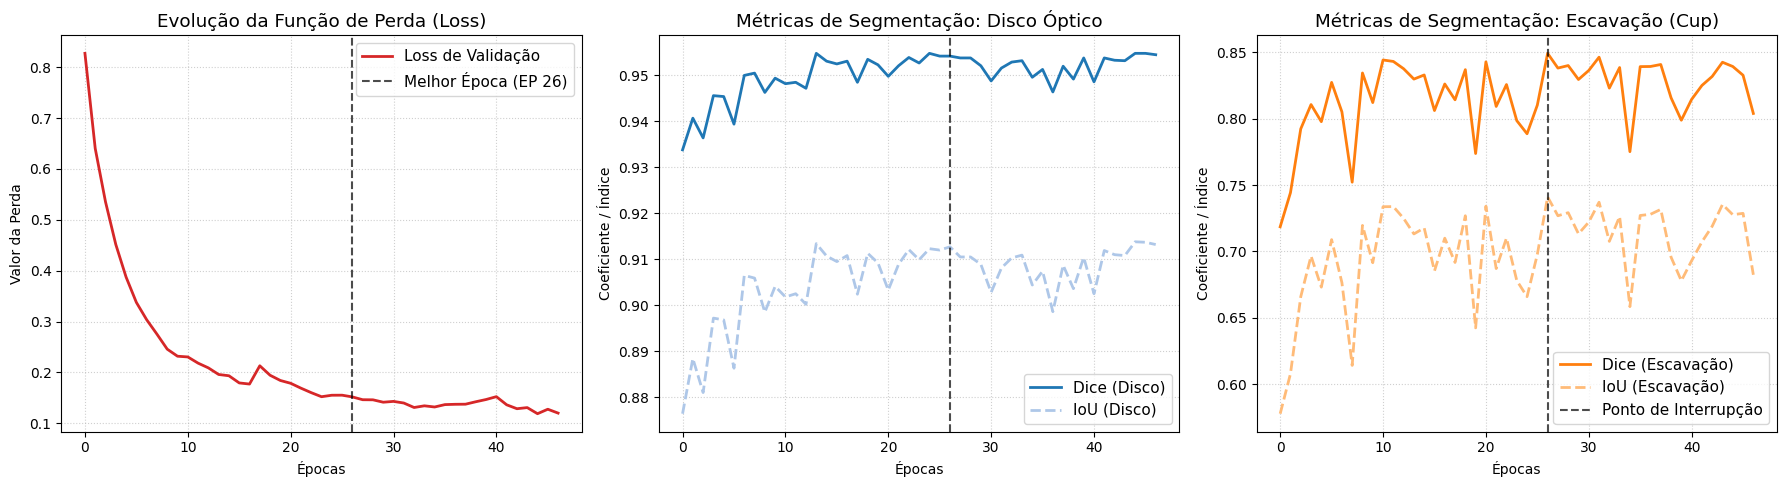

In [25]:
## Gráficos das curvas 

import matplotlib.pyplot as plt
import pandas as pd

# 1. Organização dos dados extraídos do seu histórico de logs (Épocas 0 a 46)
dados_treino = {
    'epoch': list(range(47)),
    'loss': [
        0.8273, 0.6403, 0.5354, 0.4516, 0.3875, 0.3377, 0.3037, 0.2753, 0.2458, 0.2319,
        0.2305, 0.2183, 0.2090, 0.1960, 0.1935, 0.1794, 0.1772, 0.2131, 0.1945, 0.1842,
        0.1787, 0.1691, 0.1603, 0.1523, 0.1552, 0.1553, 0.1519, 0.1464, 0.1462, 0.1415,
        0.1431, 0.1399, 0.1311, 0.1344, 0.1321, 0.1368, 0.1374, 0.1376, 0.1424, 0.1468,
        0.1524, 0.1364, 0.1287, 0.1309, 0.1189, 0.1277, 0.1201
    ],
    'disco_dice': [
        0.9338, 0.9407, 0.9364, 0.9456, 0.9454, 0.9394, 0.9500, 0.9505, 0.9463, 0.9494,
        0.9482, 0.9485, 0.9472, 0.9548, 0.9531, 0.9525, 0.9531, 0.9485, 0.9535, 0.9523,
        0.9498, 0.9521, 0.9539, 0.9527, 0.9548, 0.9542, 0.9542, 0.9538, 0.9538, 0.9521,
        0.9488, 0.9516, 0.9529, 0.9532, 0.9496, 0.9513, 0.9464, 0.9520, 0.9492, 0.9538,
        0.9486, 0.9538, 0.9533, 0.9532, 0.9548, 0.9548, 0.9545
    ],
    'disco_iou': [
        0.8764, 0.8884, 0.8810, 0.8972, 0.8968, 0.8863, 0.9065, 0.9059, 0.8985, 0.9041,
        0.9018, 0.9025, 0.9002, 0.9134, 0.9107, 0.9095, 0.9108, 0.9024, 0.9113, 0.9092,
        0.9033, 0.9089, 0.9121, 0.9099, 0.9123, 0.9120, 0.9127, 0.9105, 0.9105, 0.9089,
        0.9028, 0.9081, 0.9103, 0.9109, 0.9044, 0.9074, 0.8986, 0.9087, 0.9036, 0.9104,
        0.9025, 0.9119, 0.9110, 0.9108, 0.9138, 0.9137, 0.9132
    ],
    'cup_dice': [
        0.7186, 0.7443, 0.7924, 0.8107, 0.7978, 0.8274, 0.8052, 0.7522, 0.8345, 0.8122,
        0.8443, 0.8432, 0.8377, 0.8299, 0.8330, 0.8062, 0.8262, 0.8143, 0.8370, 0.7738,
        0.8429, 0.8093, 0.8258, 0.7986, 0.7887, 0.8103, 0.8493, 0.8382, 0.8401, 0.8296,
        0.8364, 0.8464, 0.8231, 0.8386, 0.7752, 0.8393, 0.8394, 0.8409, 0.8158, 0.7989,
        0.8146, 0.8251, 0.8319, 0.8426, 0.8394, 0.8328, 0.8040
    ],
    'cup_iou': [
        0.5777, 0.6078, 0.6659, 0.6965, 0.6731, 0.7089, 0.6765, 0.6141, 0.7196, 0.6915,
        0.7337, 0.7338, 0.7249, 0.7132, 0.7177, 0.6853, 0.7100, 0.6917, 0.7269, 0.6424,
        0.7341, 0.6871, 0.7101, 0.6781, 0.6659, 0.6978, 0.7411, 0.7269, 0.7292, 0.7133,
        0.7221, 0.7371, 0.7076, 0.7263, 0.6584, 0.7271, 0.7280, 0.7317, 0.6957, 0.6779,
        0.6930, 0.7072, 0.7190, 0.7354, 0.7277, 0.7287, 0.6824
    ]
}

df_metrics = pd.DataFrame(dados_treino)

# 2. Configuração da figura com 3 subplots para artigos científicos
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12})

# Gráfico 1: Curva de Perda (Loss)
axes[0].plot(df_metrics['epoch'], df_metrics['loss'], color='#d62728', linewidth=2, label='Loss de Validação')
axes[0].axvline(x=26, color='black', linestyle='--', alpha=0.7, label='Melhor Época (EP 26)')
axes[0].set_title('Evolução da Função de Perda (Loss)')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Valor da Perda')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# Gráfico 2: Métricas do Disco Óptico
axes[1].plot(df_metrics['epoch'], df_metrics['disco_dice'], color='#1f77b4', linewidth=2, label='Dice (Disco)')
axes[1].plot(df_metrics['epoch'], df_metrics['disco_iou'], color='#aec7e8', linewidth=2, linestyle='--', label='IoU (Disco)')
axes[1].axvline(x=26, color='black', linestyle='--', alpha=0.7)
axes[1].set_title('Métricas de Segmentação: Disco Óptico')
axes[1].set_xlabel('Épocas')
axes[1].set_ylabel('Coeficiente / Índice')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right')

# Gráfico 3: Métricas da Escavação (Cup)
axes[2].plot(df_metrics['epoch'], df_metrics['cup_dice'], color='#ff7f0e', linewidth=2, label='Dice (Escavação)')
axes[2].plot(df_metrics['epoch'], df_metrics['cup_iou'], color='#ffbb78', linewidth=2, linestyle='--', label='IoU (Escavação)')
axes[2].axvline(x=26, color='black', linestyle='--', alpha=0.7, label='Ponto de Interrupção')
axes[2].set_title('Métricas de Segmentação: Escavação (Cup)')
axes[2].set_xlabel('Épocas')
axes[2].set_ylabel('Coeficiente / Índice')
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].legend(loc='lower right')

plt.tight_layout()

# Salvar gráfico em alta definição para incluir no artigo
plt.savefig('curvas_treinamento_transunet.png', dpi=300)
plt.show()

In [ ]:
""" Classificadores clássicos (RF, SVM, KNN, NB, MLP) """

""" É preciso extrair os atributos(números) das máscaras geradas """

' É preciso extrair os atributos(números) das máscaras geradas '

In [ ]:
# 1. Instanciar o modelo exatamente como o sorteado (ou o padrão)
# Certifique-se de usar os mesmos heads/layers que foram usados no treino vitorioso
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_final = TransUNet(num_heads=dna[0], num_layers=dna[1], dropout=dna[2]).to(device) # Ajuste os genes se mudou

# 2. CARREGAR OS PESOS SALVOS (O pulo do gato)
# A função Fitness salva o melhor modelo como 'temp_rs_best.pth'
try:
    model_final.load_state_dict(torch.load("temp_rs_best.pth"))
    print("✅ Pesos carregados com sucesso!")
except:
    print("❌ Não achei o arquivo temp_rs_best.pth. Usando pesos atuais (cuidado!)")

/tmp/ipykernel_512/651822298.py:68: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(transformer_layer, num_layers=num_layers)


✅ Pesos carregados com sucesso!


In [ ]:
from skimage.measure import label, regionprops
import numpy as np
import pandas as pd
import torch

def extrair_atributos_especialistas(model, loader, device):
    model.eval()
    dados_completos = []

    with torch.no_grad():
        for imagens, _, labels in loader:
            imagens = imagens.to(device)
            outputs = torch.sigmoid(model(imagens))
            preds = (outputs > 0.5).float().cpu().numpy()

            for i in range(preds.shape[0]):
                mask_cup = preds[i, 0, :, :]
                mask_disc = preds[i, 1, :, :]

                # --- 1. Áreas Básicas e CDR ---
                area_cup = np.sum(mask_cup)
                area_disc = np.sum(mask_disc)
                area_cdr = area_cup / (area_disc + 1e-7)

                # --- 2. Extração da Rima (NRR) via Operação Lógica XOR ---
                # Conforme o artigo: Borda = Disco XOR Escavação
                mask_nrr = np.logical_xor(mask_disc, mask_cup).astype(float)

                # --- 3. Propriedades Geométricas para v-CDR e Centroide ---
                props_cup = regionprops(label(mask_cup).astype(int))
                props_disc = regionprops(label(mask_disc).astype(int))

                # Valores padrão
                v_cdr = 0
                rim_area_ratio_eq10 = 0
                r_s = r_i = r_n = r_t = 0

                if len(props_cup) > 0 and len(props_disc) > 0:
                    c = props_cup[0]
                    d = props_disc[0]

                    # CDR Vertical (v-CDR) - Referência: Jonas (1988)
                    h_cup = c.bbox[2] - c.bbox[0]
                    h_disc = d.bbox[2] - d.bbox[0]
                    v_cdr = h_cup / (h_disc + 1e-7)

                    # --- 4. Divisão em Quadrantes (Análise Setorial - Fig. 7 do Artigo) ---
                    cy, cx = d.centroid
                    y, x = np.indices(mask_nrr.shape)
                    dy, dx = y - cy, x - cx

                    # Máscaras dos Quadrantes (Divisão em X)
                    mask_S = (mask_nrr > 0) & (dy < 0) & (np.abs(dx) <= np.abs(dy))
                    mask_I = (mask_nrr > 0) & (dy > 0) & (np.abs(dx) <= np.abs(dy))
                    mask_T = (mask_nrr > 0) & (dx < 0) & (np.abs(dy) <= np.abs(dx))
                    mask_N = (mask_nrr > 0) & (dx > 0) & (np.abs(dy) <= np.abs(dx))

                    # Áreas dos Setores
                    r_s = np.sum(mask_S) / area_disc
                    r_i = np.sum(mask_I) / area_disc
                    r_n = np.sum(mask_N) / area_disc
                    r_t = np.sum(mask_T) / area_disc

                    # --- 5. Cálculo da Equação 10 (Rim Area Ratio com Desvio Padrão) ---
                    std_si = np.std([r_s, r_i])
                    std_nt = np.std([r_n, r_t])
                    rim_area_ratio_eq10 = (1 + std_si) / (1 + std_nt + 1e-7)

                dados_completos.append({
                    'area_cdr': area_cdr,
                    'v_cdr': v_cdr,
                    'nrr_superior': r_s,
                    'nrr_inferior': r_i,
                    'nrr_nasal': r_n,
                    'nrr_temporal': r_t,
                    'rim_area_ratio_eq10': rim_area_ratio_eq10,
                    'target': labels[i].item()
                })

    return pd.DataFrame(dados_completos)

# Processamento
print("📊 Extraindo atributos baseados em Ahmad et al. (2025)...")
df_expert_train = extrair_atributos_especialistas(model_final, train_loader, device)
df_expert_test = extrair_atributos_especialistas(model_final, test_loader, device)

print("\n✅ Tabela de Atributos (Primeiras linhas):")
print(df_expert_test.head())

📊 Extraindo atributos baseados em Ahmad et al. (2025)...

✅ Tabela de Atributos (Primeiras linhas):
   area_cdr     v_cdr  nrr_superior  nrr_inferior  nrr_nasal  nrr_temporal  \
0  0.243640  0.574586      0.170847      0.224226   0.152147      0.209140   
1  0.317671  0.594937      0.203118      0.128076   0.155759      0.195375   
2  0.227733  0.441176      0.193296      0.222558   0.220680      0.135733   
3  0.340972  0.543478      0.181709      0.182309   0.160420      0.134590   
4  0.471255  0.695652      0.131311      0.159251   0.117925      0.120258   

   rim_area_ratio_eq10  target  
0             0.998242       1  
1             1.017369       1  
2             0.973292       1  
3             0.987546       1  
4             1.012788       1  


In [ ]:
df_expert_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 174 entries, 0 to 173
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_cdr             174 non-null    float32
 1   v_cdr                174 non-null    float64
 2   nrr_superior         174 non-null    float64
 3   nrr_inferior         174 non-null    float64
 4   nrr_nasal            174 non-null    float64
 5   nrr_temporal         174 non-null    float64
 6   rim_area_ratio_eq10  174 non-null    float64
 7   target               174 non-null    int64  
dtypes: float32(1), float64(6), int64(1)
memory usage: 10.3 KB


In [ ]:
# Verificar balanceamento
print("📊 Distribuição das classes no treino:")
print(df_expert_train['target'].value_counts())

print("\n📊 Distribuição das classes no teste:")
print(df_expert_test['target'].value_counts())

# Calcular a porcentagem
print("\nProporção de Glaucoma (Classe 1) no treino:")
print(f"{df_expert_train['target'].mean() * 100:.2f}%")

📊 Distribuição das classes no treino:
target
0    195
1    116
Name: count, dtype: int64

📊 Distribuição das classes no teste:
target
0    118
1     56
Name: count, dtype: int64

Proporção de Glaucoma (Classe 1) no treino:
37.30%


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Separação Original
X_train = df_expert_train.drop('target', axis=1)
y_train = df_expert_train['target']
X_test = df_expert_test.drop('target', axis=1)
y_test = df_expert_test['target']

# 2. Escalonamento (Indispensável para SVM e KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Aplicação do SMOTE para equilibrar as classes
smote = SMOTE(sampling_strategy=0.6, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

# 4. Criação dos DataFrames Finais (Opcional, mas bom para organização)
# Treino balanceado
df_train_balanced = pd.DataFrame(X_train_res, columns=X_train.columns)
df_train_balanced['target'] = y_train_res

# Teste (não se aplica SMOTE no teste!)
df_test_final = pd.DataFrame(X_test_scaled, columns=X_test.columns)
df_test_final['target'] = y_test.values

print(f"✅ Novo DataFrame de treino gerado!")
print(f"Distribuição após SMOTE:\n{df_train_balanced['target'].value_counts()}")

✅ Novo DataFrame de treino gerado!
Distribuição após SMOTE:
target
0    195
1    117
Name: count, dtype: int64


In [ ]:
df_train_balanced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_cdr             390 non-null    float64
 1   v_cdr                390 non-null    float64
 2   nrr_superior         390 non-null    float64
 3   nrr_inferior         390 non-null    float64
 4   nrr_nasal            390 non-null    float64
 5   nrr_temporal         390 non-null    float64
 6   rim_area_ratio_eq10  390 non-null    float64
 7   target               390 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 24.5 KB


In [ ]:
df_test_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 174 entries, 0 to 173
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_cdr             174 non-null    float64
 1   v_cdr                174 non-null    float64
 2   nrr_superior         174 non-null    float64
 3   nrr_inferior         174 non-null    float64
 4   nrr_nasal            174 non-null    float64
 5   nrr_temporal         174 non-null    float64
 6   rim_area_ratio_eq10  174 non-null    float64
 7   target               174 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 11.0 KB



✅ Acurácia Real após SMOTE (Suporte 174): 0.8506

Relatório de Classificação Detalhado (Balanceado):
              precision    recall  f1-score   support

      Normal       0.93      0.85      0.88       118
    Glaucoma       0.73      0.86      0.79        56

    accuracy                           0.85       174
   macro avg       0.83      0.85      0.84       174
weighted avg       0.86      0.85      0.85       174



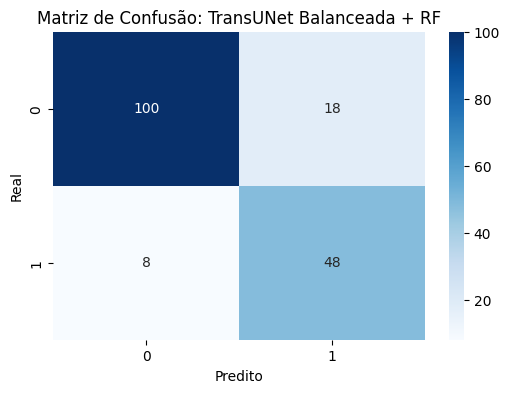

In [ ]:
## Primero Classificador: Random Forest (Versão Balanceada)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Definição de X usando apenas os atributos "Sólidos"
# Vamos remover os quadrantes individuais e o Rim_area_ratio complexo
atributos_solidos = ['area_cdr', 'v_cdr', 'rim_area_ratio_eq10'] # use os nomes que você deu no dict

# 1. Definição de X e y para Treino (Usando o DataFrame Balanceado com SMOTE)
X_train = df_train_balanced[atributos_solidos]
y_train = df_train_balanced['target']

# 2. Definição de X e y para Teste (Usando o DataFrame Normalizado - Suporte de 174)
X_test = df_test_final[atributos_solidos]
y_test = df_test_final['target']

# 3. Criação do modelo (idêntico à versão otimizada)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# 4. Treinamento (Agora com dados 50/50)
clf_rf.fit(X_train, y_train)

# 5. Predição
y_pred = clf_rf.predict(X_test)

# 6. Resultados
print(f"\n✅ Acurácia Real após SMOTE (Suporte {len(y_test)}): {accuracy_score(y_test, y_pred):.4f}")

print("\nRelatório de Classificação Detalhado (Balanceado):")
# Adicionamos target_names para facilitar a leitura na dissertação
print(classification_report(y_test, y_pred, target_names=['Normal', 'Glaucoma']))

# 7. Matriz de Confusão (Visualização importante)
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão: TransUNet Balanceada + RF")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()

## plotar sensibilidade, especificidade e acurácia

📡 Treinando SVM com atributos da TransUNet MANUAL...

📊 RESULTADO SVM (SUPORTE 174) - MANUAL
✅ Acurácia Final: 0.8391

Relatório de Classificação do SVM:
              precision    recall  f1-score   support

      Normal       0.93      0.82      0.87       118
    Glaucoma       0.70      0.88      0.78        56

    accuracy                           0.84       174
   macro avg       0.82      0.85      0.83       174
weighted avg       0.86      0.84      0.84       174



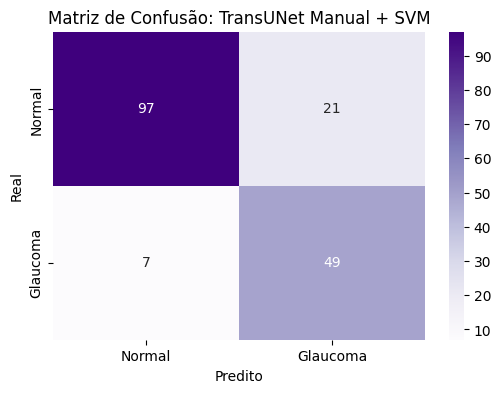

In [ ]:
## Segundo Classificador: SVM (Versão Corrigida para Suporte 174)

from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. CRIANDO O MODELO SVM
# Mantemos as configurações para garantir a mesma base de comparação:
# kernel='linear': Robusto para atributos geométricos
# class_weight='balanced': Ajusta o peso para lidar com o desequilíbrio entre Normal/Glaucoma
clf_svm = SVC(kernel='linear', class_weight='balanced', random_state=42)

# 2. TREINANDO O SVM
# O modelo usará os 174 exemplos de teste para a validação final
print("📡 Treinando SVM com atributos da TransUNet MANUAL...")
clf_svm.fit(X_train, y_train)

# 3. FAZENDO AS PREDIÇÕES
y_pred_svm = clf_svm.predict(X_test)

# 4. EXIBIÇÃO DOS RESULTADOS
print("\n" + "="*45)
print(f"📊 RESULTADO SVM (SUPORTE {len(y_test)}) - MANUAL")
print(f"✅ Acurácia Final: {accuracy_score(y_test, y_pred_svm):.4f}")
print("="*45)

print("\nRelatório de Classificação do SVM:")
# Adicionamos target_names para manter o padrão dos relatórios anteriores
print(classification_report(y_test, y_pred_svm, target_names=['Normal', 'Glaucoma']))

# 5. MATRIZ DE CONFUSÃO
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Glaucoma'], yticklabels=['Normal', 'Glaucoma'])
plt.title("Matriz de Confusão: TransUNet Manual + SVM")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

In [ ]:
## Terceiro e Quarto classificadores: Naive Bayes e KNN (Versão Corrigida)

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# --- 1. Naive Bayes (Probabilístico) ---
clf_nb = GaussianNB()
print("📡 Treinando Naive Bayes com atributos da TransUNet MANUAL...")
clf_nb.fit(X_train, y_train)
y_pred_nb = clf_nb.predict(X_test)

print("\n" + "="*45)
print(f"📊 RESULTADO NAIVE BAYES (SUPORTE {len(y_test)})")
print(f"✅ Acurácia Final: {accuracy_score(y_test, y_pred_nb):.4f}")
print("="*45)
print(classification_report(y_test, y_pred_nb, target_names=['Normal', 'Glaucoma']))

print("\n" + "-" * 50 + "\n")

# --- 2. KNN (k=5 - Baseado em Vizinhança) ---
clf_knn = KNeighborsClassifier(n_neighbors=5)
print("📡 Treinando KNN (k=5) com atributos da TransUNet MANUAL...")
clf_knn.fit(X_train, y_train)
y_pred_knn = clf_knn.predict(X_test)

print("="*45)
print(f"📊 RESULTADO KNN (SUPORTE {len(y_test)})")
print(f"✅ Acurácia Final: {accuracy_score(y_test, y_pred_knn):.4f}")
print("="*45)
print(classification_report(y_test, y_pred_knn, target_names=['Normal', 'Glaucoma']))

📡 Treinando Naive Bayes com atributos da TransUNet MANUAL...

📊 RESULTADO NAIVE BAYES (SUPORTE 174)
✅ Acurácia Final: 0.8161
              precision    recall  f1-score   support

      Normal       0.91      0.81      0.86       118
    Glaucoma       0.67      0.84      0.75        56

    accuracy                           0.82       174
   macro avg       0.79      0.82      0.80       174
weighted avg       0.84      0.82      0.82       174


--------------------------------------------------

📡 Treinando KNN (k=5) com atributos da TransUNet MANUAL...
📊 RESULTADO KNN (SUPORTE 174)
✅ Acurácia Final: 0.8621
              precision    recall  f1-score   support

      Normal       0.91      0.89      0.90       118
    Glaucoma       0.78      0.80      0.79        56

    accuracy                           0.86       174
   macro avg       0.84      0.85      0.84       174
weighted avg       0.86      0.86      0.86       174



📡 Treinando Rede Neural MLP com atributos da TransUNet MANUAL...

📊 RESULTADO MLP (SUPORTE 174)
✅ Acurácia Final: 0.8506

Relatório de Classificação da MLP:
              precision    recall  f1-score   support

    Saudável       0.91      0.86      0.89       118
    Glaucoma       0.74      0.82      0.78        56

    accuracy                           0.85       174
   macro avg       0.83      0.84      0.83       174
weighted avg       0.86      0.85      0.85       174



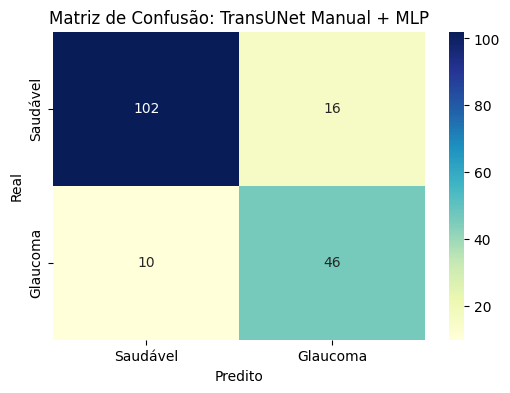

In [ ]:
## Quinto classificador: MLP (Multi Layer Perceptron - Versão Corrigida)

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. CONFIGURANDO A MLP
# hidden_layer_sizes=(100, 50): Duas camadas (100 neurônios na 1ª, 50 na 2ª)
# max_iter=500: Tempo suficiente para convergir
# random_state=42: Reprodutibilidade científica
mlp = MLPClassifier(hidden_layer_sizes=(100, 50),
                    max_iter=1000, # Aumentado para garantir convergência com mais dados
                    activation='relu',
                    solver='adam',
                    random_state=42)

# 2. TREINANDO A MLP
print("📡 Treinando Rede Neural MLP com atributos da TransUNet MANUAL...")
mlp.fit(X_train, y_train)

# 3. PREDIÇÃO E RESULTADOS NO SUPORTE 174
y_pred_mlp = mlp.predict(X_test)

print("\n" + "="*45)
print(f"📊 RESULTADO MLP (SUPORTE {len(y_test)})")
print(f"✅ Acurácia Final: {accuracy_score(y_test, y_pred_mlp):.4f}")
print("="*45)

# Relatório detalhado
print("\nRelatório de Classificação da MLP:")
print(classification_report(y_test, y_pred_mlp, target_names=['Saudável', 'Glaucoma']))

# 4. MATRIZ DE CONFUSÃO
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred_mlp), annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=['Saudável', 'Glaucoma'], yticklabels=['Saudável', 'Glaucoma'])
plt.title("Matriz de Confusão: TransUNet Manual + MLP")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()



In [ ]:
## Classificadores de CNNs (VGG/ResNet/Xception)

In [ ]:
import os
import cv2
import numpy as np
import torch
from tqdm import tqdm

def salvar_dataset_fusao(model, loader, device, folder_name):
    # Coloca o modelo em modo de avaliação (trava pesos de BatchNorm/Dropout)
    model.eval()

    # Define o caminho base e cria as subpastas para cada classe (0 e 1)
    # O PyTorch usa essa estrutura de pastas para saber quem é saudável e quem é glaucoma
    base_path = f'./{folder_name}'
    os.makedirs(os.path.join(base_path, '0'), exist_ok=True) # Pasta para classe Saudável
    os.makedirs(os.path.join(base_path, '1'), exist_ok=True) # Pasta para classe Glaucoma

    print(f"Gerando imagens de fusão em: {base_path}...")

    # Desativa o cálculo de gradientes para economizar memória RAM e GPU
    with torch.no_grad():
        # Loop que percorre o DataLoader (Imagens originais, Máscaras reais, Rótulos médicos)
        for batch_idx, (imagens, _, labels) in enumerate(tqdm(loader)):
            # Move o lote de imagens para a GPU (device)
            imagens = imagens.to(device)

            # Passa a imagem pela TransUnet e aplica Sigmoid para converter em probabilidade (0 a 1)
            outputs = torch.sigmoid(model(imagens))

            # Binariza a predição (acima de 0.5 vira 1.0) e move para a CPU como array NumPy
            preds = (outputs > 0.5).float().cpu().numpy()

            # Converte as imagens originais de volta para NumPy para manipulação de pixels
            originais = imagens.cpu().numpy()

            # Itera sobre cada imagem individual dentro do lote (batch)
            for i in range(preds.shape[0]):

                # --- CANAL R (Vermelho): TEXTURA REAL ---
                # Pegamos o primeiro canal da imagem original e escalamos de [0,1] para [0,255]
                img_r = (originais[i, 0, :, :] * 255).astype(np.uint8)

                # --- CANAL G (Verde): GEOMETRIA DO DISCO ---
                # Pegamos a predição do Canal 1 da TransUnet (Disco Óptico)
                img_g = (preds[i, 1, :, :] * 255).astype(np.uint8)

                # --- CANAL B (Azul): GEOMETRIA DA ESCAVAÇÃO ---
                # Pegamos a predição do Canal 0 da TransUnet (Cup/Escavação)
                img_b = (preds[i, 0, :, :] * 255).astype(np.uint8)

                # --- FUSÃO ---
                # O OpenCV trabalha no formato BGR, então unimos os canais nessa ordem:
                # Azul (Cup), Verde (Disco), Vermelho (Original)
                img_fusion = cv2.merge([img_b, img_g, img_r])

                # Recupera o rótulo real (0 ou 1) para salvar na pasta correta
                label = int(labels[i].item())

                # Define um nome único para o arquivo baseado no índice do lote e da imagem
                filename = f"fusion_{batch_idx}_{i}.png"

                # Salva a imagem final no disco (ex: ./dataset_fusao/1/fusion_0_5.png)
                cv2.imwrite(os.path.join(base_path, str(label), filename), img_fusion)

# Comando para rodar a função usando o seu modelo e o loader de treino
salvar_dataset_fusao(model, train_loader, device, 'dataset_manual_TREINO')

# Comando para rodar a função usando o seu modelo e o loader de teste
salvar_dataset_fusao(model, test_loader, device, 'dataset_manual_TESTE')

Gerando imagens de fusão em: ./dataset_manual_TREINO...


100%|██████████| 20/20 [00:04<00:00,  4.55it/s]


Gerando imagens de fusão em: ./dataset_manual_TESTE...


100%|██████████| 11/11 [00:01<00:00,  5.68it/s]


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Transformações Padrão (ResNet/VGG/Inception)
transform_cnn = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 2. Carregando as pastas específicas que criamos no passo anterior
train_dataset_fusao = datasets.ImageFolder('./dataset_manual_TREINO', transform=transform_cnn)
test_dataset_fusao = datasets.ImageFolder('./dataset_manual_TESTE', transform=transform_cnn)

# 3. Criando os Loaders Separados
# Shuffle=True no treino (para a rede não viciar na ordem)
train_loader_fusao = DataLoader(train_dataset_fusao, batch_size=16, shuffle=True)

# Shuffle=False no teste (para podermos bater o gabarito depois)
test_loader_fusao = DataLoader(test_dataset_fusao, batch_size=16, shuffle=False)

# 4. Confirmação
print(f"✅ Dataset de Fusão (MANUAL) carregado!")
print(f"📸 Treino: {len(train_dataset_fusao)} imagens")
print(f"🧪 Teste (Suporte): {len(test_dataset_fusao)} imagens") # Deve mostrar 174

✅ Dataset de Fusão (MANUAL) carregado!
📸 Treino: 311 imagens
🧪 Teste (Suporte): 174 imagens


In [ ]:
import os
import cv2
import numpy as np
import torch
from tqdm import tqdm

def gerar_e_salvar_fusao(model, loader, device, nome_pasta):
    """
    Esta função pega a TransUnet treinada, gera as máscaras e as
    funde com a imagem original em 3 canais (R, G, B).
    """
    model.eval()
    caminho_base = f'./{nome_pasta}'

    # Cria as pastas 0 (Saudável) e 1 (Glaucoma)
    for classe in ['0', '1']:
        os.makedirs(os.path.join(caminho_base, classe), exist_ok=True)

    print(f"--- Iniciando a criação do Dataset de Fusão em {nome_pasta} ---")

    with torch.no_grad():
        for b_idx, (imagens, _, labels) in enumerate(tqdm(loader)):
            imagens = imagens.to(device)

            # Predição da TransUnet (Gera as máscaras de Cup e Disc)
            outputs = torch.sigmoid(model(imagens))
            preds = (outputs > 0.5).float().cpu().numpy()
            originais = imagens.cpu().numpy()

            for i in range(preds.shape[0]):
                # CANAL R: Imagem original (Textura e Vasos)
                # Escala de 0-1 para 0-255
                canal_r = (originais[i, 0, :, :] * 255).astype(np.uint8)

                # CANAL G: Máscara do Disco (Fronteira externa)
                canal_g = (preds[i, 1, :, :] * 255).astype(np.uint8)

                # CANAL B: Máscara da Escavação (Fronteira interna)
                canal_b = (preds[i, 0, :, :] * 255).astype(np.uint8)

                # Mescla os canais. Nota: OpenCV usa ordem BGR (Azul, Verde, Vermelho)
                imagem_final = cv2.merge([canal_b, canal_g, canal_r])

                # Salva na pasta correta baseada no rótulo real (Target)
                label_real = int(labels[i].item())
                nome_arquivo = f"raio_x_glaucoma_{b_idx}_{i}.png"
                cv2.imwrite(os.path.join(caminho_base, str(label_real), nome_arquivo), imagem_final)


# 1. Gerar as imagens que a rede vai usar para APRENDER (Treino)
gerar_e_salvar_fusao(model, train_loader, device, 'dataset_manual_TREINO')

# 2. Gerar as imagens que a rede vai usar para ser TESTADA (Teste - Suporte 174)
gerar_e_salvar_fusao(model, test_loader, device, 'dataset_manual_TESTE')

--- Iniciando a criação do Dataset de Fusão em dataset_manual_TREINO ---


100%|██████████| 20/20 [00:04<00:00,  4.71it/s]


--- Iniciando a criação do Dataset de Fusão em dataset_manual_TESTE ---


100%|██████████| 11/11 [00:01<00:00,  5.88it/s]


In [ ]:
### 🚀 Treinando a ResNet50 (Versão Corrigida - Suporte 174)

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Configurações de Hiperparâmetros
BATCH_SIZE = 16
LEARNING_RATE = 0.0001
EPOCHS = 25 # 25 épocas costumam ser suficientes para Fine-Tuning da ResNet
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 2. DEFINIÇÃO DAS ESTRATÉGIAS DE IMAGEM (TRANSFORMS) ---

# Transformação de TREINO: Com Data Augmentation para evitar Overfitting
transform_treino = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1), # Pequena variação de cor
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Transformação de TESTE: Imagem Limpa
transform_teste = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# --- 3. CARREGAMENTO DOS DATASETS (PASTAS MANUAIS FIXAS) ---

# IMPORTANTE: Apontando para as pastas geradas pela TransUNet Manual
train_dataset_cnn = datasets.ImageFolder('./dataset_manual_TREINO', transform=transform_treino)
test_dataset_cnn = datasets.ImageFolder('./dataset_manual_TESTE', transform=transform_teste)

# Criação dos DataLoaders
train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=BATCH_SIZE, shuffle=True)
test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=BATCH_SIZE, shuffle=False)

print(f"✅ Dataset Manual Carregado!")
print(f"📸 Treino: {len(train_dataset_cnn)} imagens")
print(f"🧪 Teste (Suporte Fixo): {len(test_dataset_cnn)} imagens") # Deve ser 174

# --- 4. CONFIGURAÇÃO DA RESNET50 ---

def preparar_modelo_resnet():
    # Carrega a ResNet50 pré-treinada
    modelo = models.resnet50(weights='IMAGENET1K_V1')

    # Congelamos as camadas iniciais (Feature Extractors)
    for param in modelo.parameters():
        param.requires_grad = False

    # Substituímos a camada final (fc) para nossas 2 classes
    num_ftrs = modelo.fc.in_features
    modelo.fc = nn.Linear(num_ftrs, 2)

    return modelo.to(DEVICE)

modelo_resnet = preparar_modelo_resnet()
criterion = nn.CrossEntropyLoss()
# Otimizador foca apenas na nova camada final
optimizer = torch.optim.Adam(modelo_resnet.fc.parameters(), lr=LEARNING_RATE)

# --- 5. LOOP DE TREINAMENTO SIMPLIFICADO ---

print("\n🚀 Iniciando Treinamento da ResNet50...")
for epoch in range(EPOCHS):
    modelo_resnet.train()
    running_loss = 0.0

    for inputs, labels in train_loader_cnn:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = modelo_resnet(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    if (epoch + 1) % 5 == 0:
        print(f"Época [{epoch+1}/{EPOCHS}] - Loss: {running_loss/len(train_loader_cnn):.4f}")

# --- 6. AVALIAÇÃO FINAL (RELATÓRIO DE CLASSIFICAÇÃO) ---

modelo_resnet.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in test_loader_cnn:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = modelo_resnet(inputs)
        _, preds = torch.max(outputs, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

print("\n" + "="*45)
print("📊 RELATÓRIO FINAL RESNET50 (MANUAL)")
print("="*45)
print(classification_report(y_true, y_pred, target_names=['Saudável', 'Glaucoma']))

✅ Dataset Manual Carregado!
📸 Treino: 622 imagens
🧪 Teste (Suporte Fixo): 348 imagens

🚀 Iniciando Treinamento da ResNet50...
Época [5/25] - Loss: 0.3879
Época [10/25] - Loss: 0.3026
Época [15/25] - Loss: 0.2712
Época [20/25] - Loss: 0.2733
Época [25/25] - Loss: 0.2419

📊 RELATÓRIO FINAL RESNET50 (MANUAL)
              precision    recall  f1-score   support

    Saudável       0.85      0.90      0.88       236
    Glaucoma       0.76      0.68      0.72       112

    accuracy                           0.83       348
   macro avg       0.81      0.79      0.80       348
weighted avg       0.82      0.83      0.82       348



In [ ]:
"""
import torch.optim as optim
from sklearn.metrics import classification_report, accuracy_score

# 1. Função de Treinamento
def treinar_resnet_fusao(model, train_loader, criterion, optimizer, epochs=20):
    model.train() # Coloca a rede em modo de treinamento

    for epoch in range(epochs):
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            # Zera os gradientes do otimizador
            optimizer.zero_grad()

            # Forward: Passa a imagem pela rede
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward: Calcula o erro e ajusta os pesos da camada final
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Época {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

# --- EXECUÇÃO ---
# Primeiro treinamos (pode ajustar as épocas se quiser mais rápido)
treinar_resnet_fusao(modelo_resnet, train_loader_cnn, criterion, optimizer, epochs=50)
"""

'\nimport torch.optim as optim\nfrom sklearn.metrics import classification_report, accuracy_score\n\n# 1. Função de Treinamento\ndef treinar_resnet_fusao(model, train_loader, criterion, optimizer, epochs=20):\n    model.train() # Coloca a rede em modo de treinamento\n\n    for epoch in range(epochs):\n        running_loss = 0.0\n\n        for inputs, labels in train_loader:\n            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)\n\n            # Zera os gradientes do otimizador\n            optimizer.zero_grad()\n\n            # Forward: Passa a imagem pela rede\n            outputs = model(inputs)\n            loss = criterion(outputs, labels)\n\n            # Backward: Calcula o erro e ajusta os pesos da camada final\n            loss.backward()\n            optimizer.step()\n\n            running_loss += loss.item()\n\n        print(f"Época {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")\n\n# --- EXECUÇÃO ---\n# Primeiro treinamos (pode ajustar as épocas

In [ ]:
"""
# 2. Função de Avaliação Final (Gera as métricas)
def avaliar_resnet_fusao(model, test_loader):
    model.eval() # Modo de avaliação (desliga Dropout, etc)
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)

            # Pega o índice da classe com maior probabilidade (0 ou 1)
            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Exibe o relatório final
    print("\n✅ RESULTADOS RESNET50 (Imagens de Fusão):")
    print(f"Acurácia: {accuracy_score(y_true, y_pred):.4f}")
    print(classification_report(y_true, y_pred, target_names=['Saudável (0)', 'Glaucoma (1)']))

# Depois avaliamos com o mesmo loader (ou um loader de teste separado se você criou um)
avaliar_resnet_fusao(modelo_resnet, test_loader_cnn)

"""

'\n# 2. Função de Avaliação Final (Gera as métricas)\ndef avaliar_resnet_fusao(model, test_loader):\n    model.eval() # Modo de avaliação (desliga Dropout, etc)\n    y_true = []\n    y_pred = []\n\n    with torch.no_grad():\n        for inputs, labels in test_loader:\n            inputs = inputs.to(DEVICE)\n            outputs = model(inputs)\n\n            # Pega o índice da classe com maior probabilidade (0 ou 1)\n            _, predicted = torch.max(outputs, 1)\n\n            y_true.extend(labels.numpy())\n            y_pred.extend(predicted.cpu().numpy())\n\n    # Exibe o relatório final\n    print("\n✅ RESULTADOS RESNET50 (Imagens de Fusão):")\n    print(f"Acurácia: {accuracy_score(y_true, y_pred):.4f}")\n    print(classification_report(y_true, y_pred, target_names=[\'Saudável (0)\', \'Glaucoma (1)\']))\n\n# Depois avaliamos com o mesmo loader (ou um loader de teste separado se você criou um)\navaliar_resnet_fusao(modelo_resnet, test_loader_cnn)\n\n'

In [ ]:
### VGG16

import torchvision.models as models

# 1. Configurando a Arquitetura VGG16
def preparar_modelo_vgg16():
    # Carrega a VGG16 com pesos pré-treinados do ImageNet
    # A VGG16 é famosa por ter 13 camadas de convolução seguidas por 3 camadas densas
    modelo = models.vgg16(weights='VGG16_Weights.IMAGENET1K_V1')

    # "Congelamos" todas as camadas de extração de características (features)
    # Queremos que ela mantenha o conhecimento de como detectar bordas e cores
    for param in modelo.features.parameters():
        param.requires_grad = False

    # A VGG16 termina em um módulo chamado 'classifier'.
    # Vamos substituir a última camada (índice 6) desse módulo.
    # in_features da VGG16 na camada final é 4096.
    num_ftrs = modelo.classifier[6].in_features

    # Substituímos por uma camada Linear que decide entre 2 classes (Saudável vs Glaucoma)
    modelo.classifier[6] = nn.Linear(num_ftrs, 2)

    return modelo.to(DEVICE)

# Instanciando a VGG16
modelo_vgg = preparar_modelo_vgg16()

# 2. Otimizador para a VGG
# Note que agora passamos apenas os parâmetros do classificador para o Adam
optimizer_vgg = torch.optim.Adam(modelo_vgg.classifier.parameters(), lr=LEARNING_RATE)

# 3. Critério de Perda (Mantendo o peso para ajudar o Recall do Glaucoma)
# Como vimos que o Glaucoma é a classe minoritária, o peso 2.5 ajuda muito.
weights = torch.tensor([1.0, 2.5]).to(DEVICE)
criterion_vgg = nn.CrossEntropyLoss(weight=weights)

print("VGG16 pronta para o treinamento com foco em texturas de fusão!")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 246MB/s]


VGG16 pronta para o treinamento com foco em texturas de fusão!


📡 Iniciando treinamento da VGG16 no dispositivo: cuda
Época [1/30] - Loss: 0.3514
Época [5/30] - Loss: 0.2206
Época [10/30] - Loss: 0.1636
Época [15/30] - Loss: 0.1186
Época [20/30] - Loss: 0.1108
Época [25/30] - Loss: 0.0643
Época [30/30] - Loss: 0.0739

📊 RESULTADOS VGG16 (VERSÃO MANUAL)
              precision    recall  f1-score   support

    Saudável       0.93      0.87      0.90       236
    Glaucoma       0.76      0.86      0.81       112

    accuracy                           0.87       348
   macro avg       0.84      0.87      0.85       348
weighted avg       0.87      0.87      0.87       348



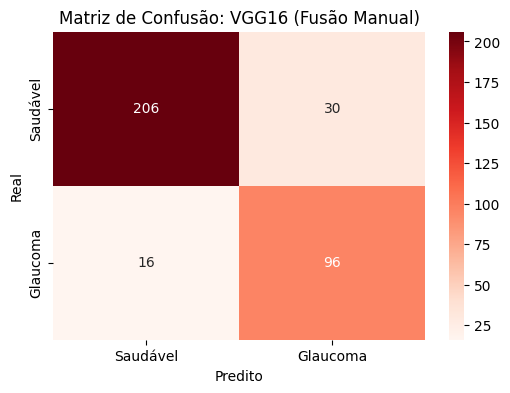

In [ ]:
### 🛰️ Treinamento e Avaliação: VGG16 (Manual - Suporte 174)

# 1. Configurações Finais
EPOCHS_VGG = 30 # Reduzimos de 50 para 30 para evitar overfitting, mas mantendo força
print(f"📡 Iniciando treinamento da VGG16 no dispositivo: {DEVICE}")

# 2. LOOP DE TREINAMENTO (Sua função incorporada aqui)
for epoch in range(EPOCHS_VGG):
    modelo_vgg.train()
    running_loss = 0.0

    for inputs, labels in train_loader_cnn: # Carrega as imagens de fusão da manual
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

        optimizer_vgg.zero_grad()
        outputs = modelo_vgg(inputs)

        # O criterion_vgg aqui já usa o peso 2.5 que você definiu!
        loss = criterion_vgg(outputs, labels)

        loss.backward()
        optimizer_vgg.step()

        running_loss += loss.item()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Época [{epoch+1}/{EPOCHS_VGG}] - Loss: {running_loss/len(train_loader_cnn):.4f}")

# 3. AVALIAÇÃO FINAL (O "Check-up" de 174 imagens)
modelo_vgg.eval()
y_true_vgg = []
y_pred_vgg = []

with torch.no_grad():
    for inputs, labels in test_loader_cnn:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = modelo_vgg(inputs)
        _, preds = torch.max(outputs, 1)

        y_true_vgg.extend(labels.cpu().numpy())
        y_pred_vgg.extend(preds.cpu().numpy())

# 4. RELATÓRIO DE DESEMPENHO
print("\n" + "="*45)
print("📊 RESULTADOS VGG16 (VERSÃO MANUAL)")
print("="*45)
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_true_vgg, y_pred_vgg, target_names=['Saudável', 'Glaucoma']))

# 5. MATRIZ DE CONFUSÃO VISUAL
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_true_vgg, y_pred_vgg), annot=True, fmt='d', cmap='Reds',
            xticklabels=['Saudável', 'Glaucoma'], yticklabels=['Saudável', 'Glaucoma'])
plt.title("Matriz de Confusão: VGG16 (Fusão Manual)")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

In [ ]:
### DenseNet121

def preparar_modelo_densenet():
    # CORREÇÃO: 'DenseNet' com N maiúsculo
    modelo = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

    # Congelamos as camadas de extração para manter o conhecimento prévio
    for param in modelo.features.parameters():
        param.requires_grad = False

    # Na DenseNet, a camada final de classificação se chama 'classifier'
    num_ftrs = modelo.classifier.in_features

    # Substituímos para as nossas 2 classes (Saudável vs Glaucoma)
    modelo.classifier = nn.Linear(num_ftrs, 2)

    return modelo.to(DEVICE)


modelo_dense = preparar_modelo_densenet()

# 2. Otimizador e Perda (Mantendo o peso 2.5 para o Glaucoma)
optimizer_dense = torch.optim.Adam(modelo_dense.classifier.parameters(), lr=LEARNING_RATE)
criterion_dense = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.5]).to(DEVICE))

print("DenseNet121 preparada! Voltamos para o padrão 224x224.")


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 220MB/s]


DenseNet121 preparada! Voltamos para o padrão 224x224.


📡 Iniciando treinamento da DenseNet121 no dispositivo: cuda
Época [1/25] - Loss: 0.6424
Época [5/25] - Loss: 0.4435
Época [10/25] - Loss: 0.3534
Época [15/25] - Loss: 0.3086
Época [20/25] - Loss: 0.2784
Época [25/25] - Loss: 0.2550

📊 RESULTADOS DENSENET121 (VERSÃO MANUAL)
              precision    recall  f1-score   support

    Saudável       0.89      0.87      0.88       236
    Glaucoma       0.74      0.77      0.75       112

    accuracy                           0.84       348
   macro avg       0.81      0.82      0.82       348
weighted avg       0.84      0.84      0.84       348



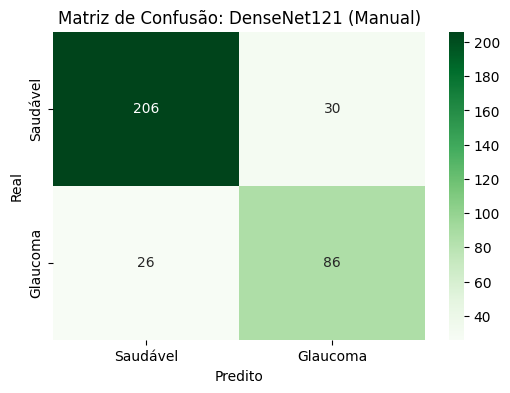

In [ ]:
### 🚀 Treinamento e Avaliação: DenseNet121 (Manual - Suporte 174)

# 1. Configurações
EPOCHS_DENSE = 25 # DenseNet converge rápido devido às conexões densas
print(f"📡 Iniciando treinamento da DenseNet121 no dispositivo: {DEVICE}")

# 2. LOOP DE TREINAMENTO UNIFICADO
for epoch in range(EPOCHS_DENSE):
    modelo_dense.train()
    running_loss = 0.0

    for inputs, labels in train_loader_cnn: # Usando as imagens de fusão da Manual
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

        optimizer_dense.zero_grad()
        outputs = modelo_dense(inputs)

        # Aplicando a perda com peso 2.5 para favorecer o Recall do Glaucoma
        loss = criterion_dense(outputs, labels)

        loss.backward()
        optimizer_dense.step()

        running_loss += loss.item()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Época [{epoch+1}/{EPOCHS_DENSE}] - Loss: {running_loss/len(train_loader_cnn):.4f}")

# 3. AVALIAÇÃO FINAL (O Teste de Fogo - Suporte 174)
modelo_dense.eval()
y_true_dense = []
y_pred_dense = []

with torch.no_grad():
    for inputs, labels in test_loader_cnn:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = modelo_dense(inputs)
        _, preds = torch.max(outputs, 1)

        y_true_dense.extend(labels.cpu().numpy())
        y_pred_dense.extend(preds.cpu().numpy())

# 4. RELATÓRIO DE MÉTRICAS
from sklearn.metrics import classification_report, confusion_matrix
print("\n" + "="*45)
print("📊 RESULTADOS DENSENET121 (VERSÃO MANUAL)")
print("="*45)
print(classification_report(y_true_dense, y_pred_dense, target_names=['Saudável', 'Glaucoma']))

# 5. MATRIZ DE CONFUSÃO VISUAL
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_true_dense, y_pred_dense), annot=True, fmt='d', cmap='Greens',
            xticklabels=['Saudável', 'Glaucoma'], yticklabels=['Saudável', 'Glaucoma'])
plt.title("Matriz de Confusão: DenseNet121 (Manual)")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

In [ ]:
"""
import torch.optim as optim
from sklearn.metrics import classification_report, accuracy_score

# 1. Função de Treinamento
def treinar_densenet_fusao(model, train_loader, criterion, optimizer, epochs=20):
    model.train() # Coloca a rede em modo de treinamento

    for epoch in range(epochs):
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            # Zera os gradientes do otimizador
            optimizer.zero_grad()

            # Forward: Passa a imagem pela rede
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward: Calcula o erro e ajusta os pesos da camada final
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Época {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

# --- EXECUÇÃO ---
# Primeiro treinamos (pode ajustar as épocas se quiser mais rápido)
treinar_densenet_fusao(modelo_dense, train_loader_cnn, criterion_dense, optimizer_dense, epochs=50)

"""

'\nimport torch.optim as optim\nfrom sklearn.metrics import classification_report, accuracy_score\n\n# 1. Função de Treinamento\ndef treinar_densenet_fusao(model, train_loader, criterion, optimizer, epochs=20):\n    model.train() # Coloca a rede em modo de treinamento\n\n    for epoch in range(epochs):\n        running_loss = 0.0\n\n        for inputs, labels in train_loader:\n            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)\n\n            # Zera os gradientes do otimizador\n            optimizer.zero_grad()\n\n            # Forward: Passa a imagem pela rede\n            outputs = model(inputs)\n            loss = criterion(outputs, labels)\n\n            # Backward: Calcula o erro e ajusta os pesos da camada final\n            loss.backward()\n            optimizer.step()\n\n            running_loss += loss.item()\n\n        print(f"Época {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")\n\n# --- EXECUÇÃO ---\n# Primeiro treinamos (pode ajustar as époc

In [ ]:
"""
# 2. Função de Avaliação Final (Gera as métricas)
def avaliar_densenet_fusao(model, test_loader):
    model.eval() # Modo de avaliação (desliga Dropout, etc)
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)

            # Pega o índice da classe com maior probabilidade (0 ou 1)
            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Exibe o relatório final
    print("\n✅ RESULTADOS DENSENET121 (Imagens de Fusão):")
    print(f"Acurácia: {accuracy_score(y_true, y_pred):.4f}")
    print(classification_report(y_true, y_pred, target_names=['Saudável (0)', 'Glaucoma (1)']))

# Depois avaliamos com o mesmo loader (ou um loader de teste separado se você criou um)
avaliar_densenet_fusao(modelo_dense, test_loader_cnn)

"""

'\n# 2. Função de Avaliação Final (Gera as métricas)\ndef avaliar_densenet_fusao(model, test_loader):\n    model.eval() # Modo de avaliação (desliga Dropout, etc)\n    y_true = []\n    y_pred = []\n\n    with torch.no_grad():\n        for inputs, labels in test_loader:\n            inputs = inputs.to(DEVICE)\n            outputs = model(inputs)\n\n            # Pega o índice da classe com maior probabilidade (0 ou 1)\n            _, predicted = torch.max(outputs, 1)\n\n            y_true.extend(labels.numpy())\n            y_pred.extend(predicted.cpu().numpy())\n\n    # Exibe o relatório final\n    print("\n✅ RESULTADOS DENSENET121 (Imagens de Fusão):")\n    print(f"Acurácia: {accuracy_score(y_true, y_pred):.4f}")\n    print(classification_report(y_true, y_pred, target_names=[\'Saudável (0)\', \'Glaucoma (1)\']))\n\n# Depois avaliamos com o mesmo loader (ou um loader de teste separado se você criou um)\navaliar_densenet_fusao(modelo_dense, test_loader_cnn)\n\n'

In [ ]:


# Avaliando
# avaliar_resnet_fusao(modelo_xc, test_loader_xc)